# Statistical Analysis, Hypothesis Testing & Data Transformations

## Objectives of this Notebook
#### 1.Perform univariate statistical analysis of numerical and categorical variables.
#### 2.Study relationships between delivery performance,customer reviews and order characteristics.
#### 3.Conduct bivariate statistical tests and calculate effect sizes.
#### 4.Apply appropriate transformations to skewed numerical variables.
#### 5.Encode categorical and cyclical variables for further analysis.
#### 6.Calculate effect sizes to understand the practical significance of observed relationships.
#### 7.Export statistical summarizes and transformed datasets for subsequent analysis.

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import spearmanr, pearsonr
from scipy.stats import mannwhitneyu, kruskal, chi2_contingency
sns.set_theme(style="whitegrid")

## 1.Load and Profile the Processed Datasets

In [52]:
master_orders = pd.read_csv("../PROCESSED_DATA/master_orders.csv")
master_sellers = pd.read_csv("../PROCESSED_DATA/master_sellers.csv")
cleaned_products = pd.read_csv("../PROCESSED_DATA/cleaned_products.csv")
cleaned_items = pd.read_csv("../PROCESSED_DATA/cleaned_items.csv")
cleaned_reviews = pd.read_csv("../PROCESSED_DATA/cleaned_reviews.csv")

### 1.1 Dataset Dimensions and Initial Inspection

In [53]:
datasets = {
    "master_orders": master_orders,
    "master_sellers": master_sellers,
    "cleaned_products": cleaned_products,
    "cleaned_items": cleaned_items,
    "cleaned_reviews": cleaned_reviews
}

for name, data in datasets.items():
    print(f"{name}'s Shape: {data.shape}")
    print(f"{name}'s Columns:")
    print(list(data.columns)) 
    print("-" * 40) 


master_orders's Shape: (99441, 59)
master_orders's Columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state', 'item_count', 'distinct_products', 'distinct_sellers', 'primary_seller_id', 'primary_product_id', 'primary_category', 'total_price', 'total_freight', 'total_weight_g', 'total_volume_cm3', 'shipping_limit_date', 'order_total_value', 'freight_ratio', 'payment_total', 'max_installments', 'payment_methods_count', 'primary_payment_type', 'review_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'has_comment', 'seller_zip_code_prefix', 'seller_city', 'seller_state', 'cust_lat', 'cust_lng', 'seller_lat', 'seller_lng', 'approval_hours', 'seller_handling_days', 'carrier_transit_days', 'total_delivery_days', 'estimated_de

In [54]:
# Orders
master_orders.head(2)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,valid_timestamps_flag,is_late,lateness_bucket,distance_km,is_cross_state,purchase_date,purchase_year,purchase_month,purchase_dayofweek,purchase_hour
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,...,1,0.0,Early (>1d early),18.681711,0,2017-10-02,2017,10,0,10
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,...,1,0.0,Early (>1d early),861.035367,1,2018-07-24,2018,7,1,20


In [55]:
master_sellers.head(2)

,seller_id,total_orders,total_items,total_revenue,total_freight,avg_price,avg_freight,avg_weight_g,avg_handling_days,median_handling_days,...,avg_review_score,low_review_rate,distinct_categories,states_served,avg_distance_km,seller_zip_code_prefix,seller_city,seller_state,freight_ratio,cross_state_share
0,0015a82c2db000af6aaaf3ae2ecb0532,3,3,2685.00,63.06,895.000000,21.020000,11800.000000,2.804352,1.728322,...,3.666667,0.333333,1,2,606.589740,9080,santo andre,SP,0.023486,1.000000
1,001cca7ae9ae17fb1caed9dfb1094831,200,239,25080.03,8854.14,104.937364,37.046611,8973.849372,2.179816,1.671863,...,3.902542,0.188285,2,18,807.971737,29156,cariacica,ES,0.353035,0.974895


In [56]:
cleaned_products.head(2)

,product_id,product_category_name,product_name_length,product_description_length,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,product_volume_cm3
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,perfumery,2240.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,art,10800.0


In [57]:
cleaned_items.head(2)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name_english,product_weight_g,product_volume_cm3
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29,cool_stuff,650.0,3528.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93,pet_shop,30000.0,60000.0


In [58]:
cleaned_reviews.head(2)

,order_id,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,has_comment
0,bd2c2c3a4d59e68fb14a526745572883,0574e3efaf2a10ee2d0c45b1ed544c84,4,NaN,NaN,2018-08-31 00:00:00,0
1,529a65336debb1c3e3327d7d67dc733d,f542d0ff698f5272fbd13deca2349582,5,Excelente,NaN,2018-08-31 00:00:00,0


## Univariate Statistical Analysis

### Purpose : Univariate analysis examines one variable at a time to understand its distribution , central tendency , variability and frequency.

### 2.1 Identification of Numerical and Categorical Variables

In [59]:
date_columns = {
    "master_orders": [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "shipping_limit_date",
        "review_creation_date",
        "purchase_date"
    ],

    "master_sellers": [],

    "cleaned_products": [],

    "cleaned_items": [
        "shipping_limit_date"
    ],

    "cleaned_reviews": [
        "review_creation_date"
    ]
}

for name, columns in date_columns.items():

    df = datasets[name]

    for col in columns:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col], errors="coerce")

print("Date conversion completed for all datasets.")

Date conversion completed for all datasets.


In [60]:

binary_names = [
    "has_comment",
    "is_late",
    "is_cross_state",
    "seller_shipped_late",
    "valid_timestamps_flag"
]

ordinal_names = [
    "review_score"
]

geographic_names = [
    "cust_lat",
    "cust_lng",
    "seller_lat",
    "seller_lng"
]


In [61]:

for name, df in datasets.items():

    # Identifier and geographic code columns
    identifier_columns = [
        col for col in df.columns
        if col.lower().endswith("_id")
        or col.lower().endswith("_zip_code_prefix")
    ]

    # Datetime variables
    datetime_columns = df.select_dtypes(
        include=["datetime"]
    ).columns.tolist()

    # Binary variables
    binary_columns = [
        col for col in df.columns
        if col in binary_names
    ]

    # Ordinal variables
    ordinal_columns = [
        col for col in df.columns
        if col in ordinal_names
    ]

    # Geographic coordinate variables
    geographic_columns = [
        col for col in df.columns
        if col in geographic_names
    ]

    # Numerical variables
    numerical_columns = [
        col for col in df.select_dtypes(include=["number"]).columns
        if col not in identifier_columns
        and col not in binary_columns
        and col not in ordinal_columns
        and col not in geographic_columns
    ]

    # Categorical variables
    categorical_columns = [
        col for col in df.select_dtypes(
            include=["object", "category"]
        ).columns
        if col not in identifier_columns
    ]

    print("\n" + "=" * 70)
    print(name.upper())
    print("=" * 70)

    print("\nNumerical Variables:")
    print(numerical_columns)

    print("\nCategorical Variables:")
    print(categorical_columns)

    print("\nBinary Variables:")
    print(binary_columns)

    print("\nOrdinal Variables:")
    print(ordinal_columns)

    print("\nDatetime Variables:")
    print(datetime_columns)

    print("\nGeographic Coordinate Variables:")
    print(geographic_columns)

    print("\nIdentifier / Geographic Code Variables:")
    print(identifier_columns)



MASTER_ORDERS

Numerical Variables:
['item_count', 'distinct_products', 'distinct_sellers', 'total_price', 'total_freight', 'total_weight_g', 'total_volume_cm3', 'order_total_value', 'freight_ratio', 'payment_total', 'max_installments', 'payment_methods_count', 'approval_hours', 'seller_handling_days', 'carrier_transit_days', 'total_delivery_days', 'estimated_delivery_days', 'days_late', 'distance_km', 'purchase_year', 'purchase_month', 'purchase_dayofweek', 'purchase_hour']

Categorical Variables:
['order_status', 'customer_city', 'customer_state', 'primary_category', 'primary_payment_type', 'review_comment_title', 'review_comment_message', 'seller_city', 'seller_state', 'lateness_bucket']

Binary Variables:
['has_comment', 'seller_shipped_late', 'valid_timestamps_flag', 'is_late', 'is_cross_state']

Ordinal Variables:
['review_score']

Datetime Variables:
['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimat

In [62]:
for name, df in datasets.items():

    print("\n" + "=" * 60)
    print(name.upper())
    print("=" * 60)

    print("Dataset Shape:", df.shape)

    print("\nData Type Distribution:")
    print(df.dtypes.value_counts())

    print("\nMissing Values:")
    print(df.isnull().sum().sum())


MASTER_ORDERS
Dataset Shape: (99441, 59)

Data Type Distribution:
float64           27
object            16
datetime64[ns]     8
int64              8
Name: count, dtype: int64

Missing Values:
187534

MASTER_SELLERS
Dataset Shape: (3095, 25)

Data Type Distribution:
float64    17
int64       5
object      3
Name: count, dtype: int64

Missing Values:
751

CLEANED_PRODUCTS
Dataset Shape: (32951, 11)

Data Type Distribution:
float64    8
object     3
Name: count, dtype: int64

Missing Values:
2450

CLEANED_ITEMS
Dataset Shape: (112650, 10)

Data Type Distribution:
object            4
float64           4
int64             1
datetime64[ns]    1
Name: count, dtype: int64

Missing Values:
36

CLEANED_REVIEWS
Dataset Shape: (98673, 7)

Data Type Distribution:
object            4
int64             2
datetime64[ns]    1
Name: count, dtype: int64

Missing Values:
145020


### Section 2.2 - Descriptive Statistical Analysis

In [63]:
# Orders data

columns_orders = [
    "total_price","total_freight","approval_hours",
    "seller_handling_days","carrier_transit_days",
    "total_delivery_days","days_late","distance_km","review_score"
]

columns_sellers = [
    "total_revenue" , "avg_handling_days","avg_transit_days",
    "avg_delivery_days","avg_days_late","late_rate","avg_review_score"
]

columns_items = [
    "price","freight_value","product_weight_g",
    "product_volume_cm3"
]

columns_products = [
    "product_weight_g","product_volume_cm3",
    "product_photos_qty","product_name_length",
    "product_description_length"
]

In [64]:
analysis_datasets = {
    "Orders": (master_orders, columns_orders),
    "Sellers": (master_sellers, columns_sellers),
    "Items": (cleaned_items, columns_items),
    "Products": (cleaned_products, columns_products)
}

In [65]:
descriptive_results = {}

for dataset_name, (df, columns) in analysis_datasets.items():

    results = []

    for col in columns:

        data = pd.to_numeric(df[col], errors="coerce").dropna()

        if data.empty:
            continue

        mode_values = data.mode()

        results.append({
            "Variable": col,
            "Count": data.count(),
            "Mean": data.mean(),
            "Median": data.median(),
            "Mode": mode_values.iloc[0] if not mode_values.empty else np.nan,
            "Minimum": data.min(),
            "Maximum": data.max(),
            "Variance": data.var(),
            "Standard Deviation": data.std(),
            "Q1": data.quantile(0.25),
            "Q3": data.quantile(0.75),
            "IQR": data.quantile(0.75) - data.quantile(0.25),
            "Skewness": data.skew(),
            "Kurtosis": data.kurt()
        })

    descriptive_results[dataset_name] = pd.DataFrame(results)

    print(f"\n{dataset_name.upper()} DESCRIPTIVE STATISTICS")
    display(descriptive_results[dataset_name].round(3))


ORDERS DESCRIPTIVE STATISTICS


,Variable,Count,Mean,Median,Mode,Minimum,Maximum,Variance,Standard Deviation,Q1,Q3,IQR,Skewness,Kurtosis
0,total_price,98666,137.754,86.900,59.900,0.850,13440.000,44371.377,210.645,45.900,149.900,104.000,9.728,266.067
1,total_freight,98666,22.824,17.170,15.100,0.000,1794.960,468.762,21.651,13.850,24.040,10.190,12.053,565.342
2,approval_hours,99281,10.419,0.343,0.000,0.000,4509.181,677.978,26.038,0.215,14.581,14.366,56.975,9122.952
3,seller_handling_days,97644,2.805,1.818,4.000,-171.219,125.763,12.598,3.549,0.876,3.580,2.705,3.666,116.465
4,carrier_transit_days,96475,9.331,7.100,3.000,-16.096,205.191,76.740,8.760,4.100,12.029,7.929,4.550,53.076
5,total_delivery_days,96476,12.559,10.218,2.069,0.533,209.629,91.136,9.547,6.766,15.720,8.954,3.833,39.308
6,days_late,96476,-11.179,-11.949,-12.386,-146.016,188.975,103.757,10.186,-16.244,-6.390,9.854,2.009,28.020
7,distance_km,98174,601.289,433.737,0.000,0.000,3579.340,352717.095,593.900,184.565,799.094,614.528,1.653,2.493
8,review_score,98673,4.086,5.000,5.000,1.000,5.000,1.816,1.348,4.000,5.000,1.000,-1.364,0.508



SELLERS DESCRIPTIVE STATISTICS


,Variable,Count,Mean,Median,Mode,Minimum,Maximum,Variance,Standard Deviation,Q1,Q3,IQR,Skewness,Kurtosis
0,total_revenue,3095,4391.484,821.480,29.900,3.500,229472.630,1.938220e+08,13921.997,208.850,3280.830,3071.980,9.048,106.462
1,avg_handling_days,2977,3.230,2.168,4.000,-17.842,61.151,1.552600e+01,3.940,1.336,3.684,2.348,5.110,43.151
2,avg_transit_days,2970,8.514,7.901,3.000,-4.943,186.400,3.251500e+01,5.702,5.640,10.372,4.733,11.644,325.161
3,avg_delivery_days,2970,12.165,11.124,1.214,1.214,189.863,5.047900e+01,7.105,8.294,14.242,5.948,7.248,141.406
4,avg_days_late,2970,-11.594,-11.283,-65.322,-65.322,167.708,6.412800e+01,8.008,-14.756,-8.391,6.364,3.578,89.344
5,late_rate,2970,0.084,0.000,0.000,0.000,1.000,2.900000e-02,0.170,0.000,0.100,0.100,3.617,15.042
6,avg_review_score,3090,3.972,4.167,5.000,1.000,5.000,9.490000e-01,0.974,3.714,4.602,0.888,-1.550,2.290



ITEMS DESCRIPTIVE STATISTICS


,Variable,Count,Mean,Median,Mode,Minimum,Maximum,Variance,Standard Deviation,Q1,Q3,IQR,Skewness,Kurtosis
0,price,112650,120.654,74.99,59.9,0.85,6735.00,3.372142e+04,183.634,39.90,134.90,95.00,7.923,120.828
1,freight_value,112650,19.990,16.26,15.1,0.00,409.68,2.498420e+02,15.806,13.08,21.15,8.07,5.640,59.788
2,product_weight_g,112632,2093.672,700.00,200.0,0.00,40425.00,1.407448e+07,3751.597,300.00,1800.00,1500.00,3.599,16.265
3,product_volume_cm3,112632,15243.710,6480.00,8000.0,168.00,296208.00,5.484273e+08,23418.525,2851.50,18375.00,15523.50,4.076,25.609



PRODUCTS DESCRIPTIVE STATISTICS


,Variable,Count,Mean,Median,Mode,Minimum,Maximum,Variance,Standard Deviation,Q1,Q3,IQR,Skewness,Kurtosis
0,product_weight_g,32949,2276.472,700.0,200.0,0.0,40425.0,1.833586e+07,4282.039,300.0,1900.0,1600.0,3.605,15.134
1,product_volume_cm3,32949,16564.097,6840.0,8000.0,168.0,296208.0,7.320835e+08,27057.042,2880.0,18480.0,15600.0,4.176,24.621
2,product_photos_qty,32341,2.189,1.0,1.0,1.0,20.0,3.016000e+00,1.737,1.0,3.0,2.0,2.193,7.264
3,product_name_length,32341,48.477,51.0,60.0,5.0,76.0,1.049750e+02,10.246,42.0,57.0,15.0,-0.903,0.193
4,product_description_length,32341,771.495,595.0,404.0,4.0,3992.0,4.033713e+05,635.115,339.0,972.0,633.0,1.962,4.829


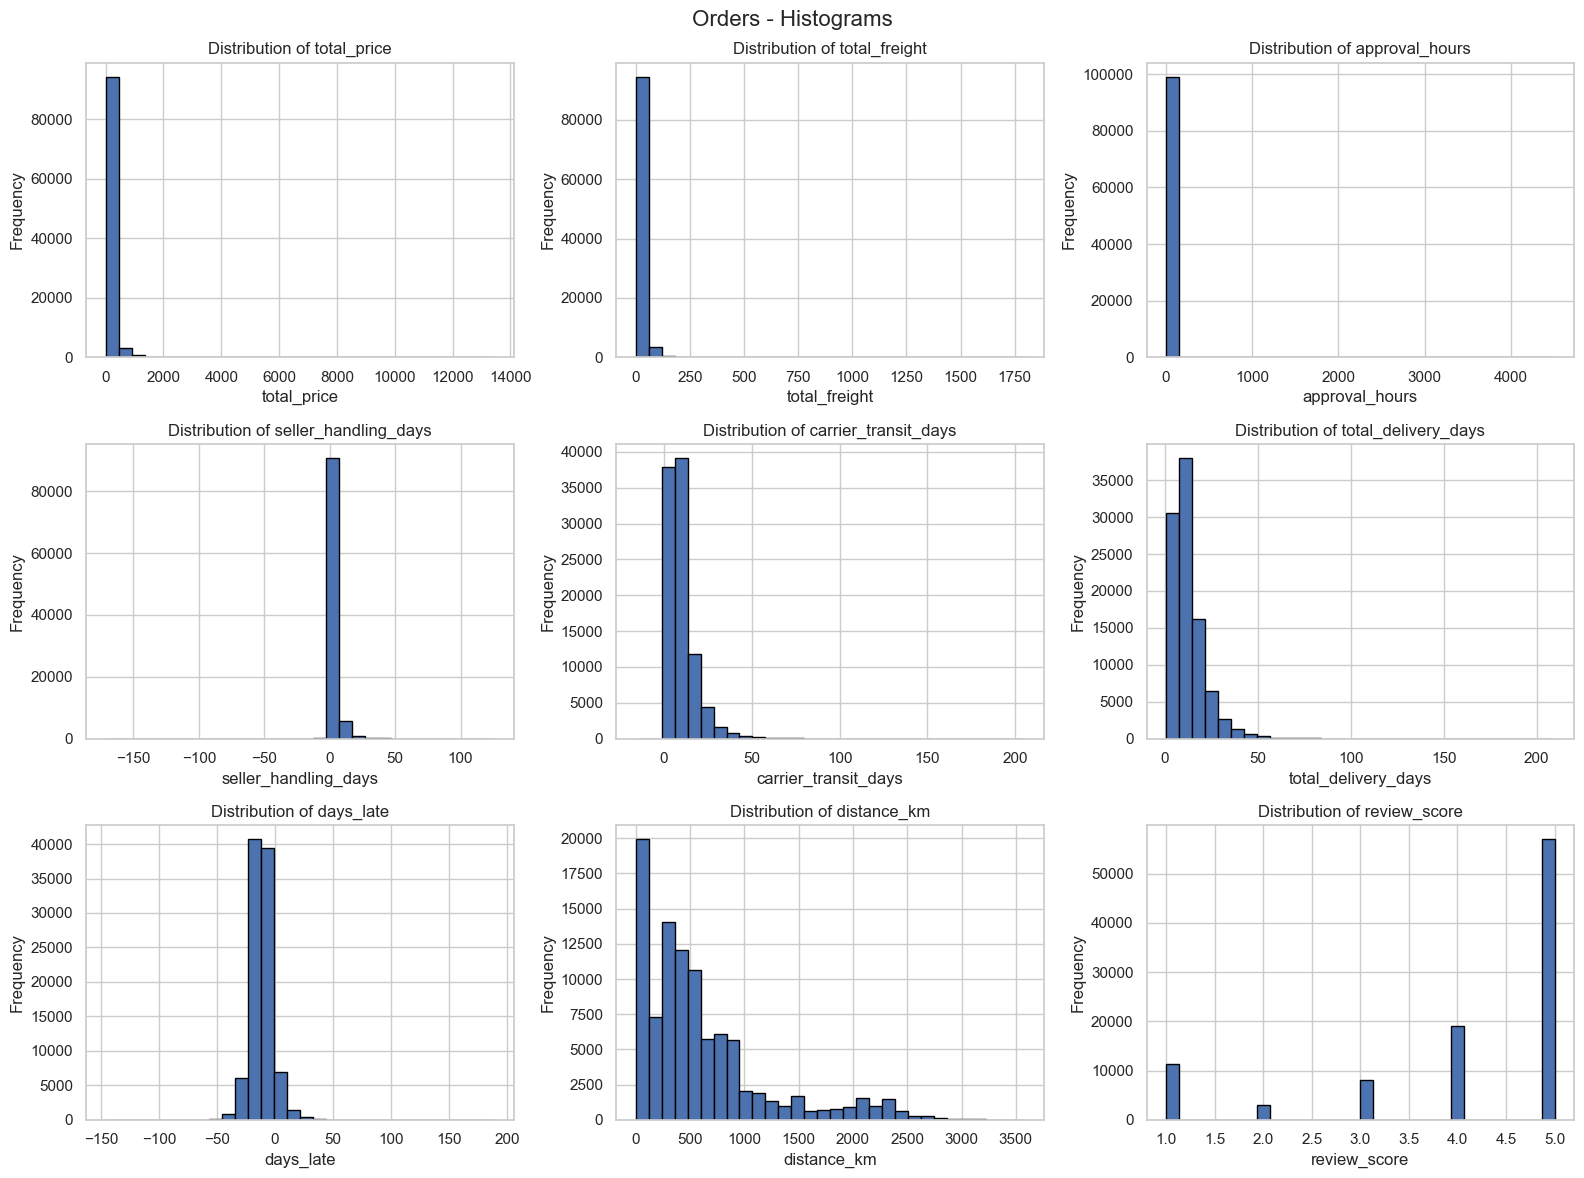

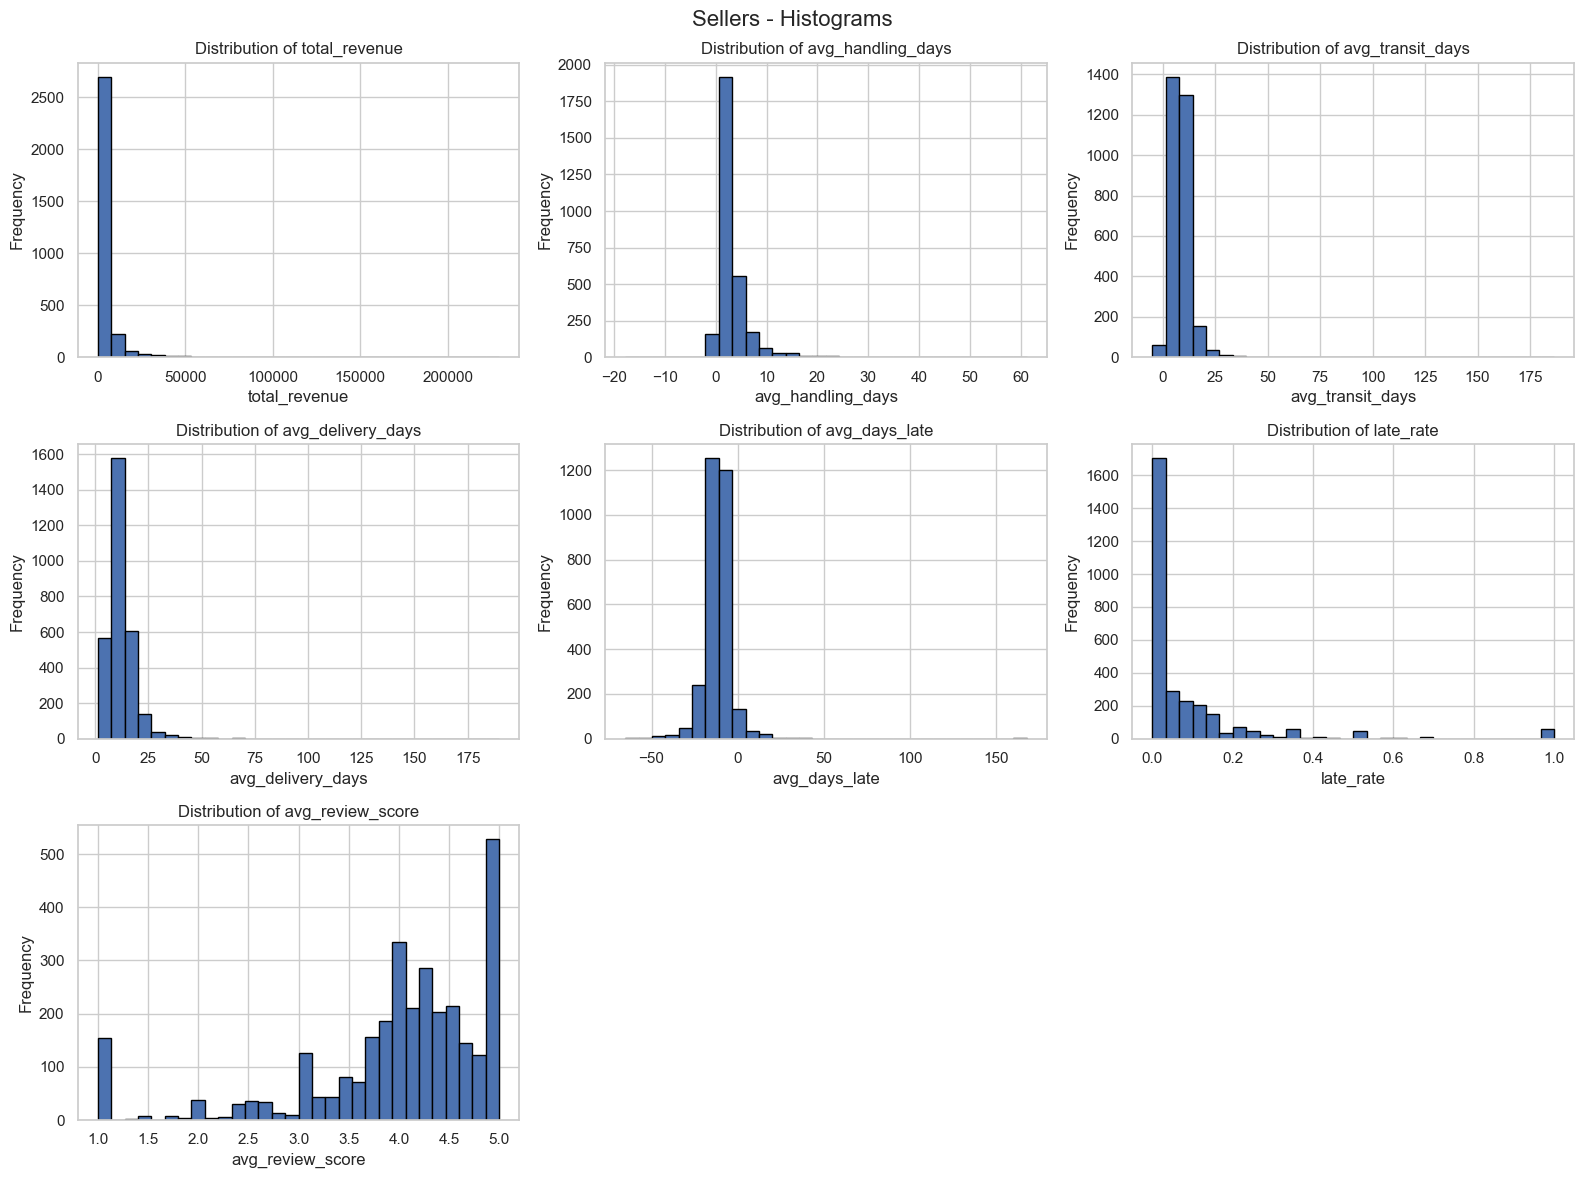

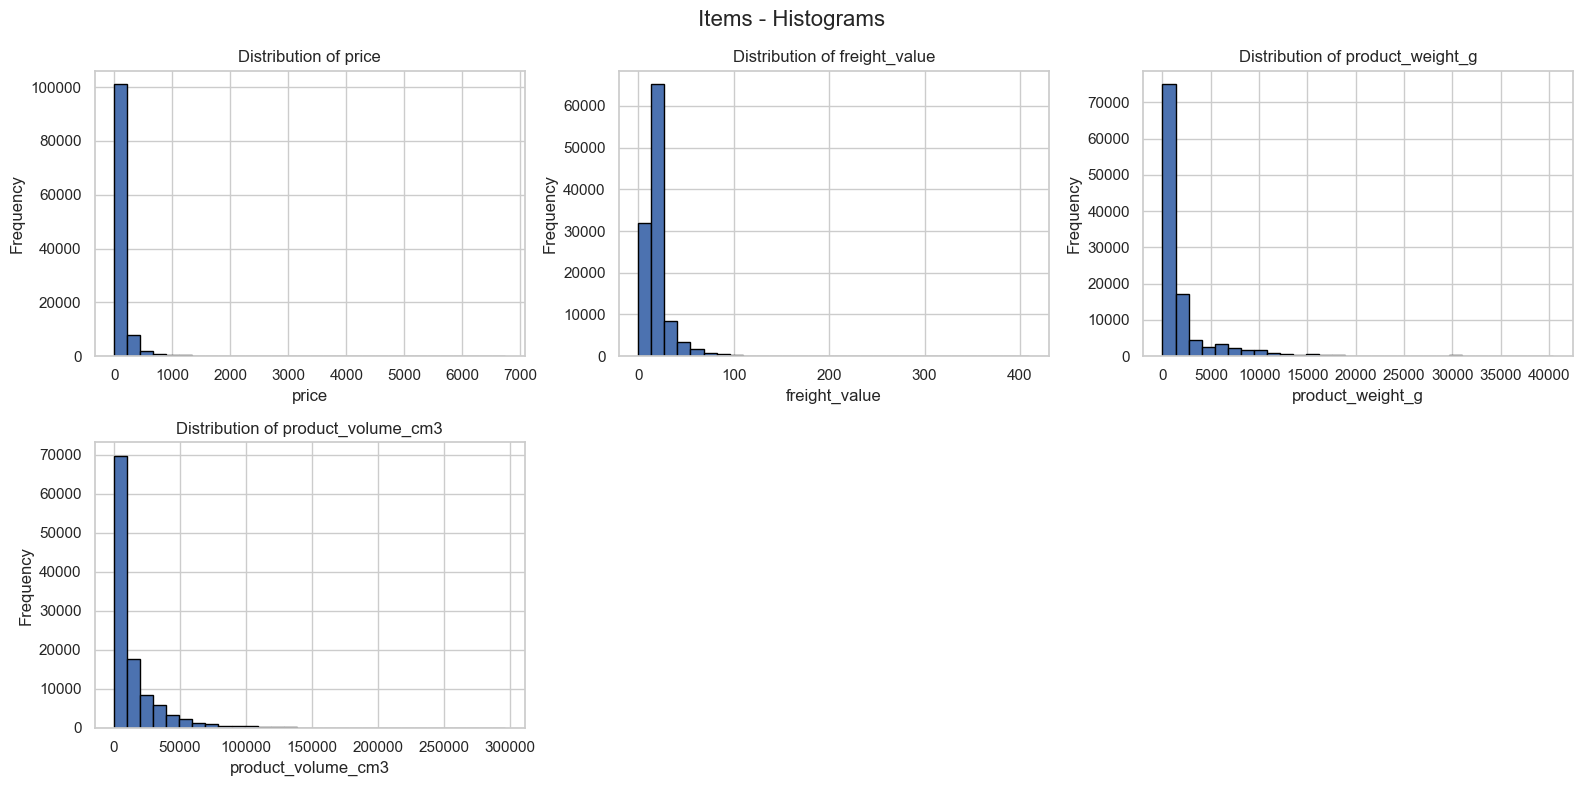

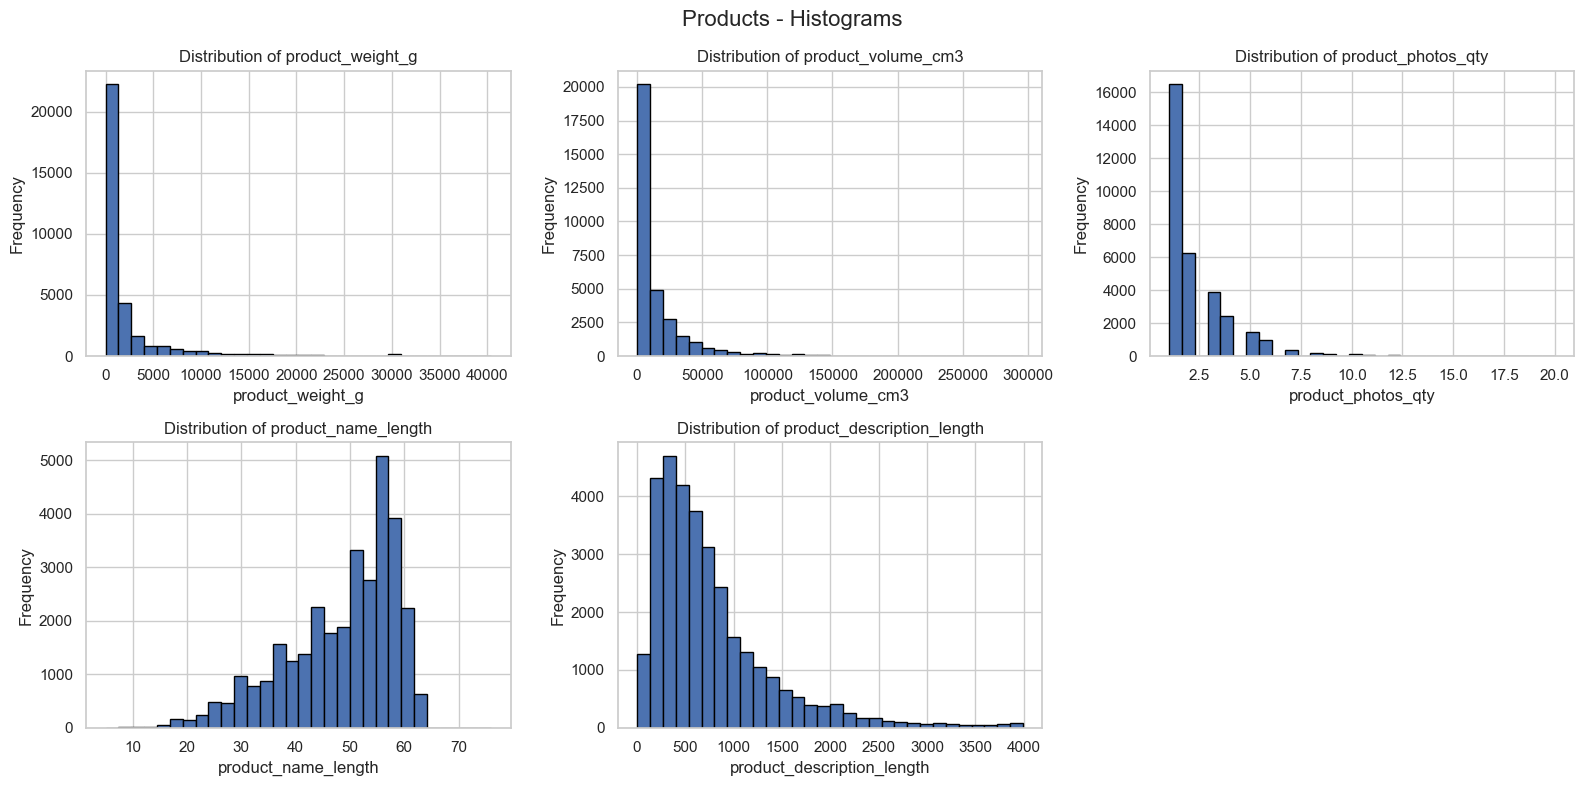

In [66]:
for dataset_name, (df, columns) in analysis_datasets.items():

    n_cols = 3
    n_rows = int(np.ceil(len(columns) / n_cols))

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(16, 4 * n_rows)
    )

    axes = np.array(axes).flatten()

    for i, col in enumerate(columns):

        data = pd.to_numeric(df[col], errors="coerce").dropna()

        axes[i].hist(data, bins=30, edgecolor="black")
        axes[i].set_title(f"Distribution of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Frequency")

    for j in range(len(columns), len(axes)):
        axes[j].set_visible(False)

    fig.suptitle(f"{dataset_name} - Histograms", fontsize=16)
    plt.tight_layout()
    plt.show()

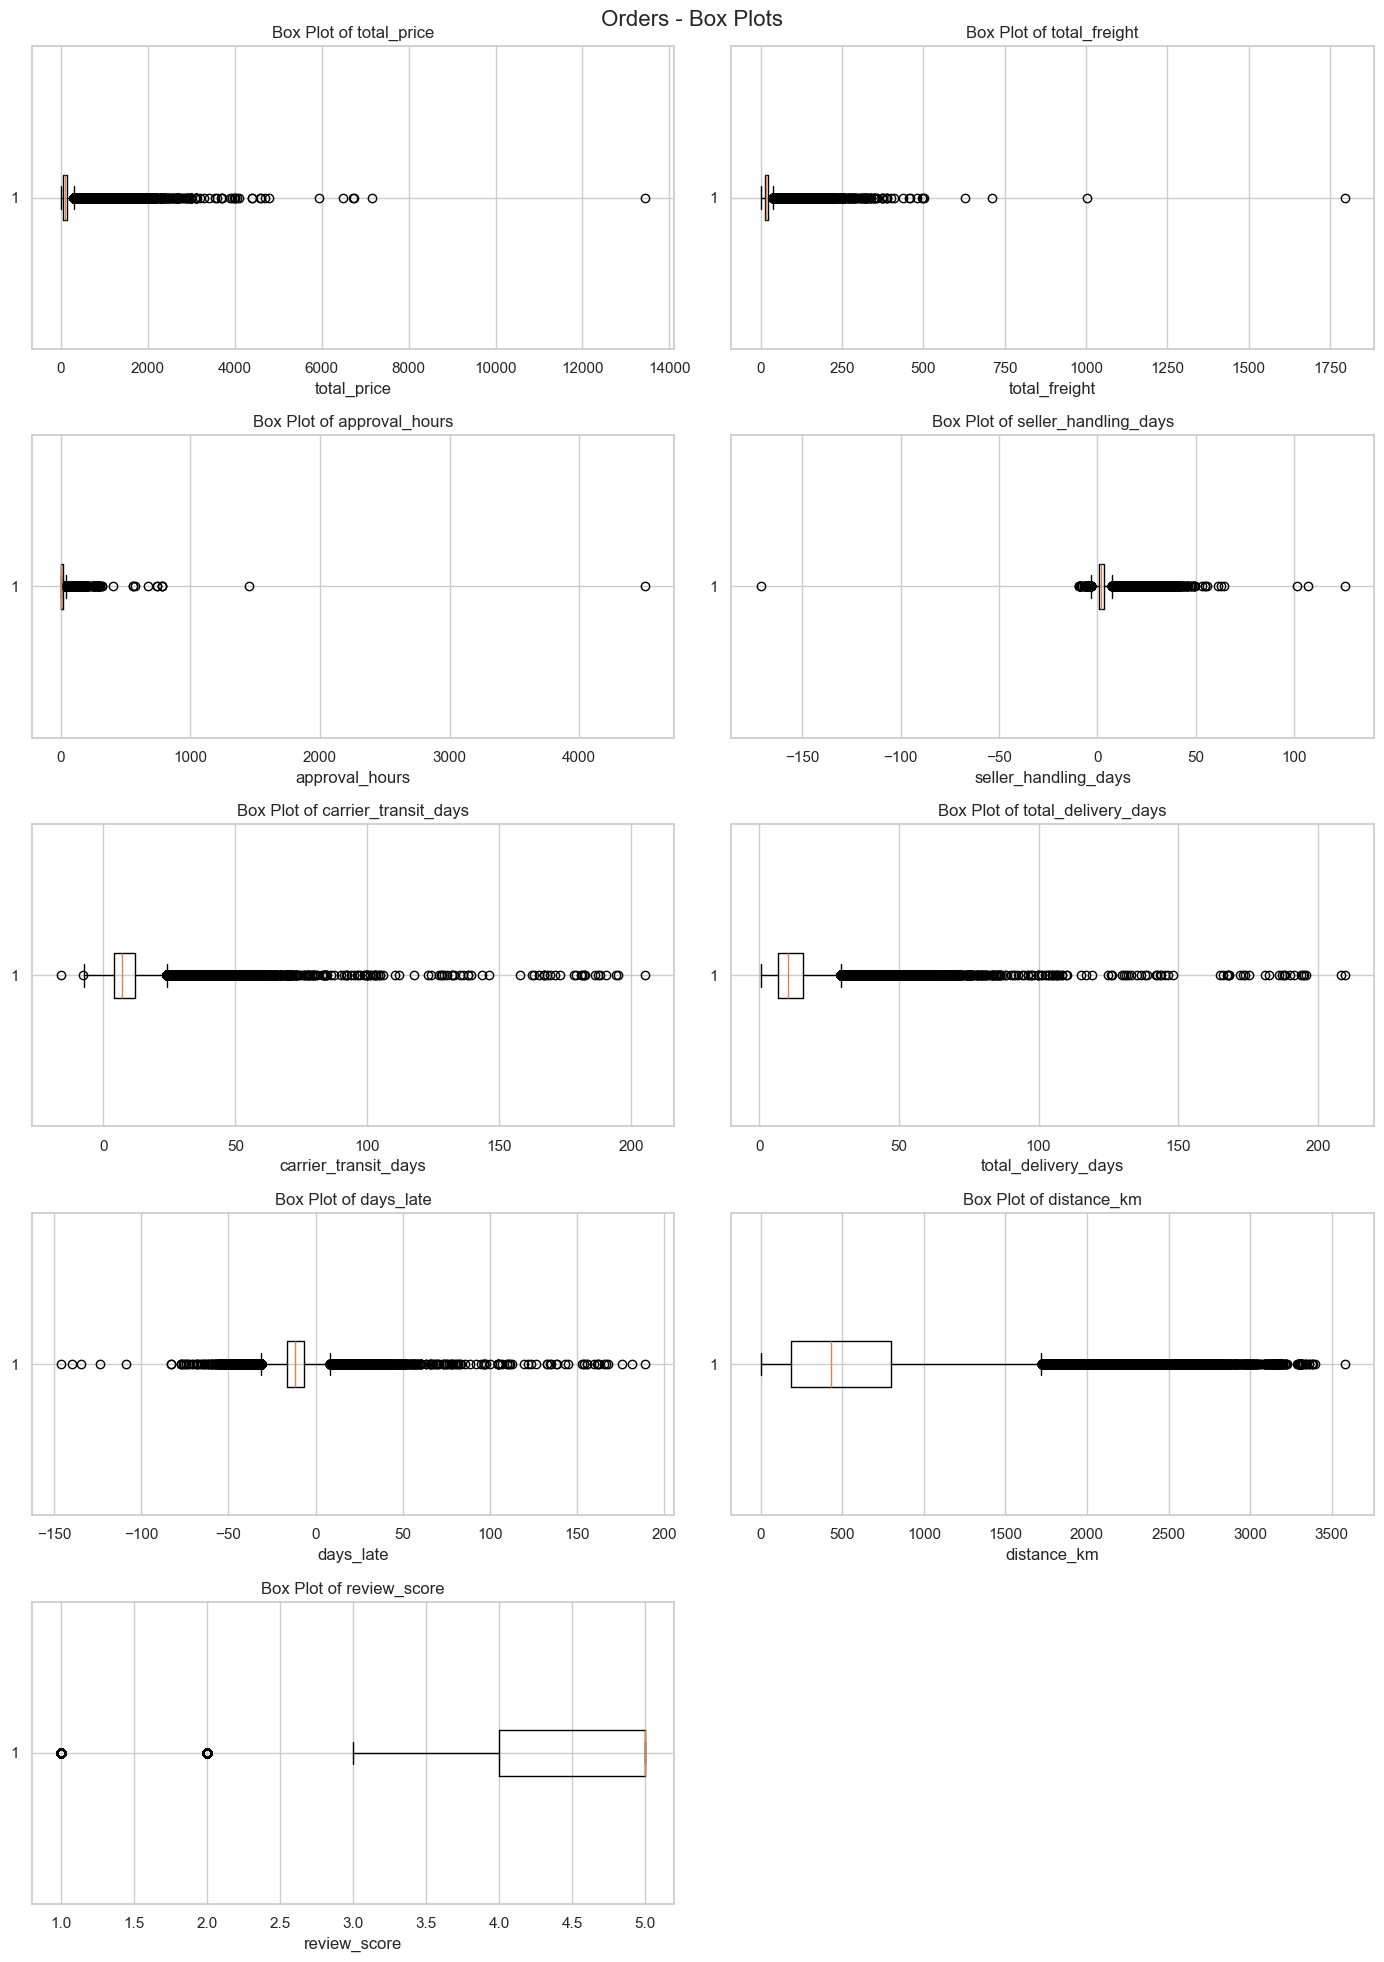

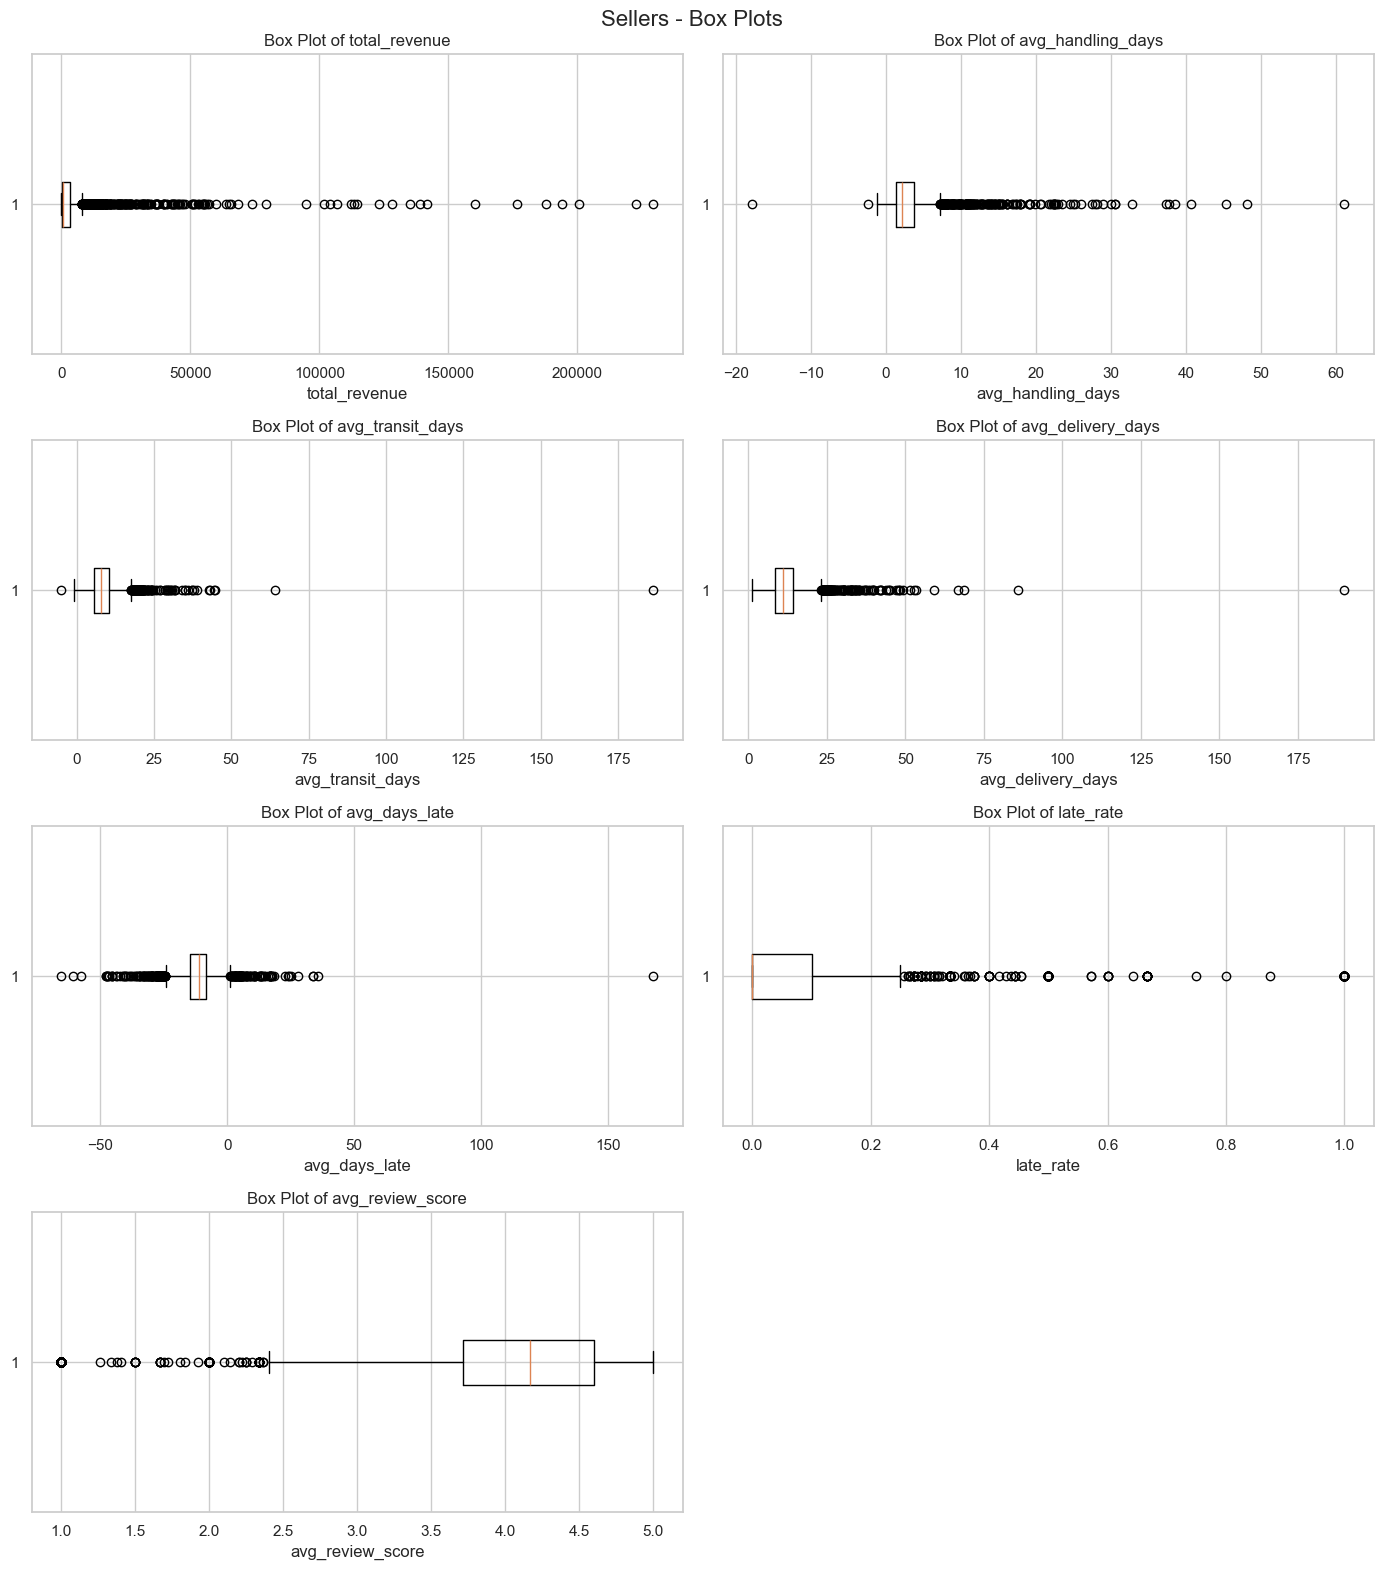

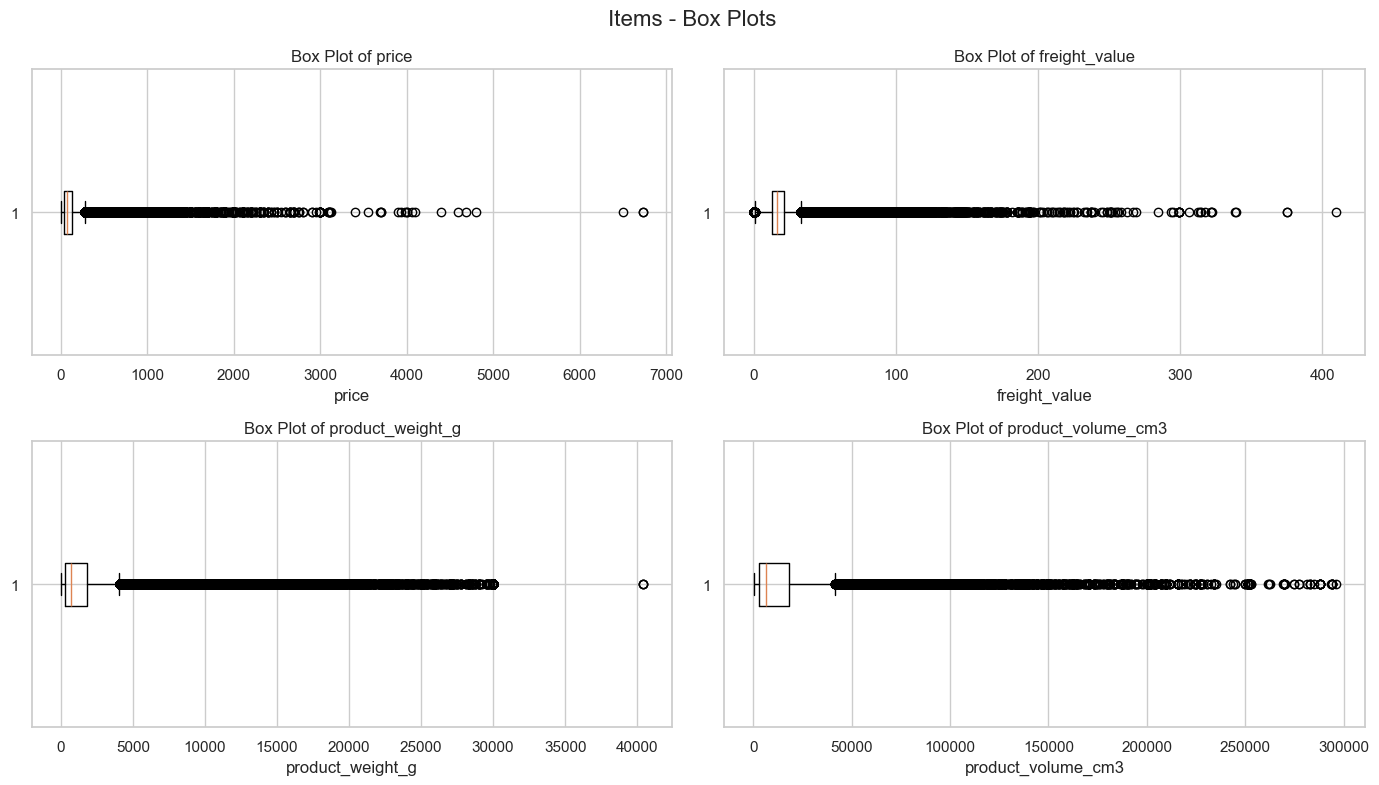

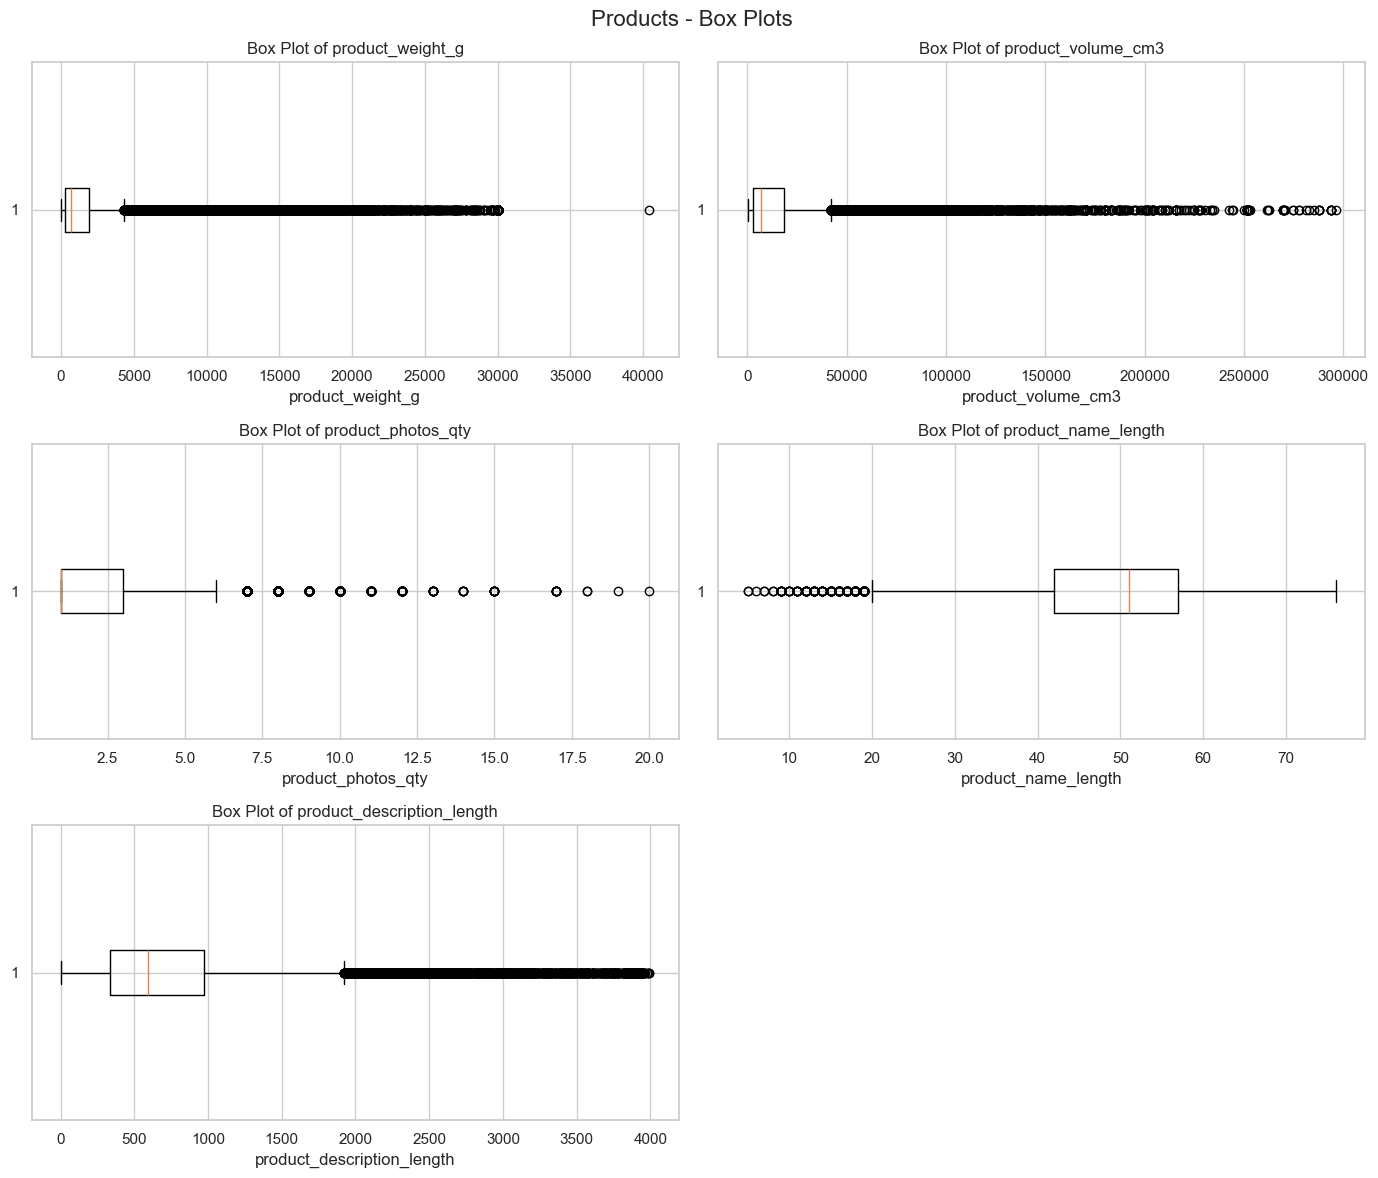

In [67]:
for dataset_name, (df, columns) in analysis_datasets.items():

    n_cols = 2
    n_rows = int(np.ceil(len(columns) / n_cols))

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(14, 4 * n_rows)
    )

    axes = np.array(axes).flatten()

    for i, col in enumerate(columns):

        data = pd.to_numeric(df[col], errors="coerce").dropna()

        axes[i].boxplot(data, vert=False)
        axes[i].set_title(f"Box Plot of {col}")
        axes[i].set_xlabel(col)

    for j in range(len(columns), len(axes)):
        axes[j].set_visible(False)

    fig.suptitle(f"{dataset_name} - Box Plots", fontsize=16)
    plt.tight_layout()
    plt.show()

### Observations

**1. Order-level analysis**

- The average order price is 137.75, whereas the median is 86.90. This difference, along with a skewness of 9.728, indicates a strongly right-skewed distribution. Most orders have relatively lower prices, while a small number of orders have substantially higher values.
- Freight charges also show strong positive skewness (12.053), with an average of 22.82 and a median of 17.17.
- The average approval time is 10.42 hours, but its median is only 0.34 hours. Its very high skewness (56.975) suggests that most orders are approved relatively quickly, while a small number experience exceptionally long approval times.
- The average total delivery duration is 12.56 days, compared with a median of 10.22 days. Delivery durations show considerable variation, with a maximum of 209.63 days.
- The mean days_late is -11.18 days, indicating that orders were delivered earlier than their estimated dates on average. However, positive maximum values show that some orders experienced substantial delays.
- Customer review scores have a mean of 4.09 and a median of 5, indicating that ratings are concentrated towards the higher end of the scale.

**2. Seller-level analysis**

- Seller revenue has a mean of 4,391.48 and a median of 821.48, with strong positive skewness (9.048). This indicates substantial differences in revenue across sellers, with a relatively small number generating much higher revenue.
- Average seller handling time is 3.23 days, while average transit time is 8.51 days. This suggests that transportation accounts for a larger portion of delivery duration than seller handling on average.
- The average late delivery rate across sellers is 0.084, equivalent to approximately 8.4%.
- Average seller review scores are relatively high, with a mean of 3.97 and a median of 4.17.

**3. Item-level analysis**

- Item prices have a mean of 120.65 and a median of 74.99, indicating a positively skewed distribution.
- Freight value also shows positive skewness, with a mean of 19.99 and a median of 16.26.
- Product weight and volume show considerable variation. Their means are substantially higher than their medians, indicating that a smaller number of heavier and larger products influence the overall averages.

**4. Product-level analysis**

- Product weight has a mean of 2,276.47 g and a median of 700 g, indicating a positively skewed distribution.
- Product volume also shows substantial variation, with a mean of 16,564.10 cm³ and a median of 6,840 cm³.
- The average number of product photographs is approximately 2.19, while the median is 1.
- Product name length shows slight negative skewness (-0.903), whereas product description length is positively skewed (1.962).

### Overall Conclusion

The univariate analysis reveals that several important numerical variables in the Olist dataset are highly skewed, particularly order prices, freight charges, approval times, seller revenue and product dimensions. In many cases, the mean is considerably higher than the median, indicating the influence of extreme observations.

The delivery-related statistics show that carrier transit time is longer than seller handling time on average. Although the average delivery lateness is negative, indicating early delivery relative to estimated dates, the presence of positive lateness values demonstrates that delayed deliveries still occur.

Seller performance also varies considerably in terms of revenue, delivery duration and lateness. Customer review scores are generally concentrated towards higher ratings.

The histograms and box plots complement these findings by showing the distributions and potential extreme observations. These results indicate that numerical transformations may be useful for selected highly skewed variables in subsequent analysis. Potential outliers should be investigated further rather than automatically removed, as they may represent genuine transactions or unusual delivery experiences.

## 2.3 Bivariate Analysis

### Purpose

Bivariate analysis examines the relationship between two variables to identify patterns, associations and dependencies within the Olist e-commerce dataset.

In this project, the analysis focuses on relationships between delivery performance, customer review scores, order characteristics and seller performance. It helps investigate whether delivery delays are associated with lower customer ratings, whether transportation distance is related to delivery duration, and how order characteristics vary with delivery performance.

Numerical relationships are explored using correlation analysis and visualizations. The findings will help identify important relationships for subsequent hypothesis testing and effect size calculations.

Correlation indicates association between variables and does not necessarily imply causation.

In [68]:
# Order-level relationships
order_pairs = [
    ("days_late", "review_score"),
    ("distance_km", "total_delivery_days"),
    ("distance_km", "days_late"),
    ("total_delivery_days", "review_score")
]

# Item-level relationships
item_pairs = [
    ("product_weight_g", "freight_value"),
    ("product_volume_cm3", "freight_value"),
    ("price", "freight_value")
]

In [69]:
def calculate_correlations(df, pairs, dataset_name):
    results = []

    for col1, col2 in pairs:
        temp = df[[col1, col2]].dropna()

        pearson_corr, pearson_p = pearsonr(
            temp[col1], temp[col2]
        )

        spearman_corr, spearman_p = spearmanr(
            temp[col1], temp[col2]
        )

        results.append({
            "Dataset": dataset_name,
            "Variable 1": col1,
            "Variable 2": col2,
            "Sample Size": len(temp),
            "Pearson Correlation": pearson_corr,
            "Pearson p-value": pearson_p,
            "Spearman Correlation": spearman_corr,
            "Spearman p-value": spearman_p
        })

    return pd.DataFrame(results)


order_correlations = calculate_correlations(
    master_orders, order_pairs, "Orders"
)

item_correlations = calculate_correlations(
    cleaned_items, item_pairs, "Items"
)

correlation_results = pd.concat(
    [order_correlations, item_correlations],
    ignore_index=True
)

correlation_results

,Dataset,Variable 1,Variable 2,Sample Size,Pearson Correlation,Pearson p-value,Spearman Correlation,Spearman p-value
0,Orders,days_late,review_score,95830,-0.266682,0.000000e+00,-0.175810,0.0
1,Orders,distance_km,total_delivery_days,95997,0.393615,0.000000e+00,0.542453,0.0
2,Orders,distance_km,days_late,95997,-0.075622,9.648838e-122,-0.179078,0.0
3,Orders,total_delivery_days,review_score,95830,-0.334097,0.000000e+00,-0.234655,0.0
4,Items,product_weight_g,freight_value,112632,0.610420,0.000000e+00,0.446591,0.0
5,Items,product_volume_cm3,freight_value,112632,0.587270,0.000000e+00,0.368587,0.0
6,Items,price,freight_value,112650,0.414204,0.000000e+00,0.434190,0.0


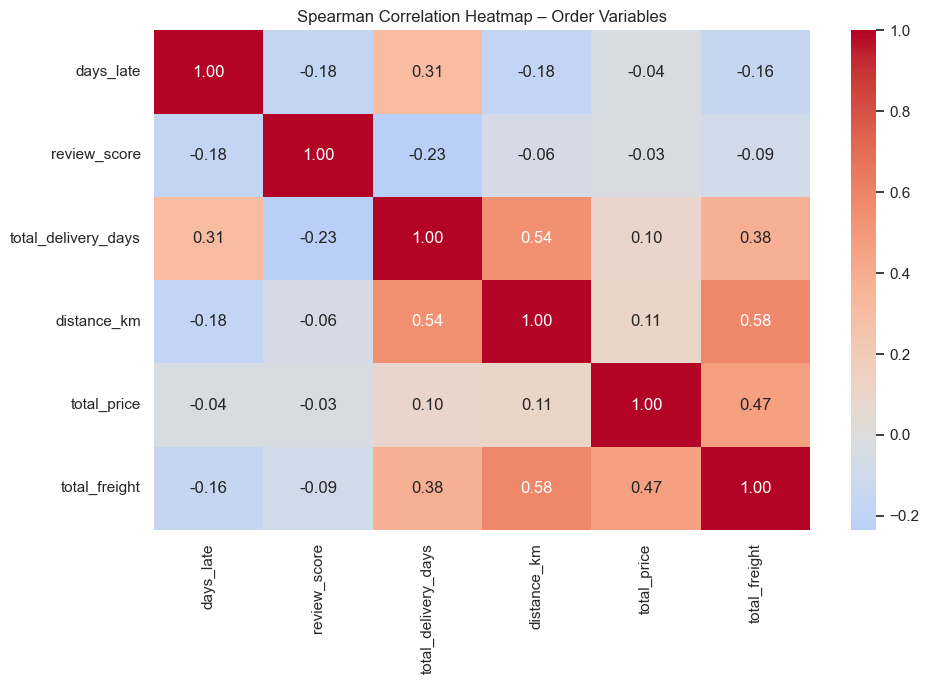

In [70]:
selected_columns = [
    "days_late",
    "review_score",
    "total_delivery_days",
    "distance_km",
    "total_price",
    "total_freight"
]

correlation_matrix = master_orders[
    selected_columns
].corr(method="spearman")

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Spearman Correlation Heatmap – Order Variables")
plt.tight_layout()
plt.show()

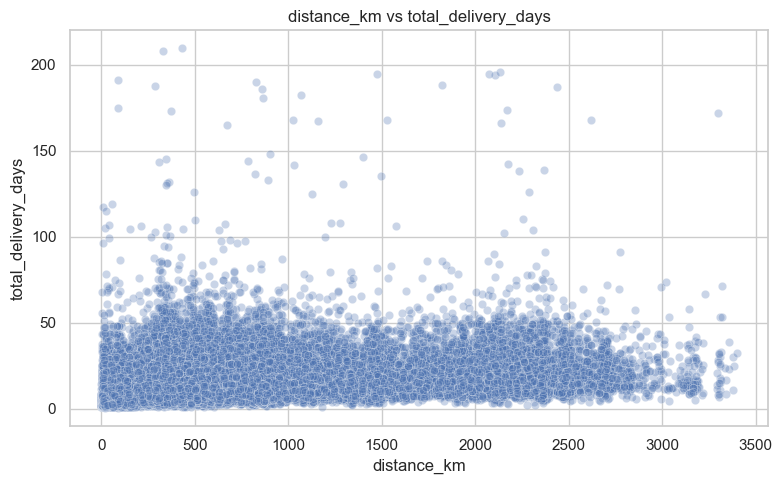

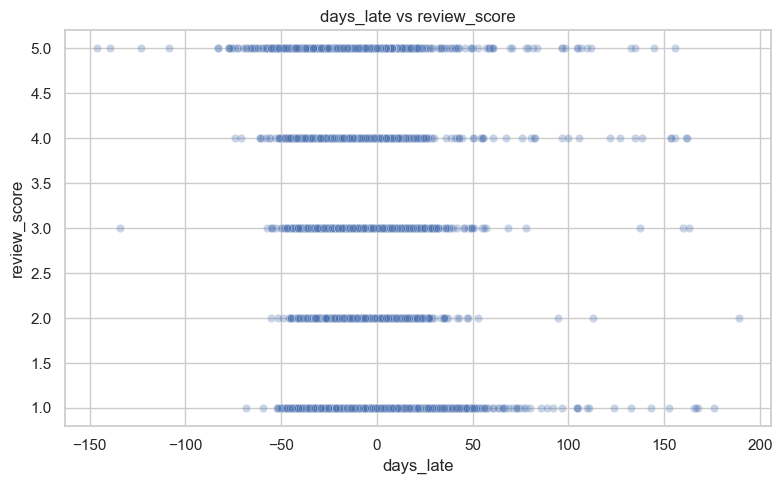

In [71]:
scatter_pairs = [
    ("distance_km", "total_delivery_days"),
    ("days_late", "review_score")
]

for x, y in scatter_pairs:

    temp = master_orders[[x, y]].dropna()

    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=temp,
        x=x,
        y=y,
        alpha=0.3
    )

    plt.title(f"{x} vs {y}")
    plt.tight_layout()
    plt.show()

In [72]:
def assign_lateness_bucket(days):
    if pd.isna(days):
        return np.nan
    elif days < -1:
        return "Early"
    elif days <= 0:
        return "On Time"
    elif days <= 3:
        return "1-3 Days Late"
    elif days <= 7:
        return "4-7 Days Late"
    else:
        return ">7 Days Late"


master_orders["lateness_bucket"] = (
    master_orders["days_late"].apply(assign_lateness_bucket)
)

bucket_order = [
    "Early",
    "On Time",
    "1-3 Days Late",
    "4-7 Days Late",
    ">7 Days Late"
]

review_by_lateness = (
    master_orders
    .dropna(subset=["review_score", "lateness_bucket"])
    .groupby("lateness_bucket", observed=False)
    .agg(
        order_count=("review_score", "count"),
        average_review_score=("review_score", "mean"),
        median_review_score=("review_score", "median")
    )
    .reindex(bucket_order)
)

review_by_lateness

,order_count,average_review_score,median_review_score
lateness_bucket,,,
Early,86718,4.296190,5.0
On Time,1450,4.157931,5.0
1-3 Days Late,2636,3.765933,4.0
4-7 Days Late,1773,2.318105,1.0
>7 Days Late,3253,1.727329,1.0


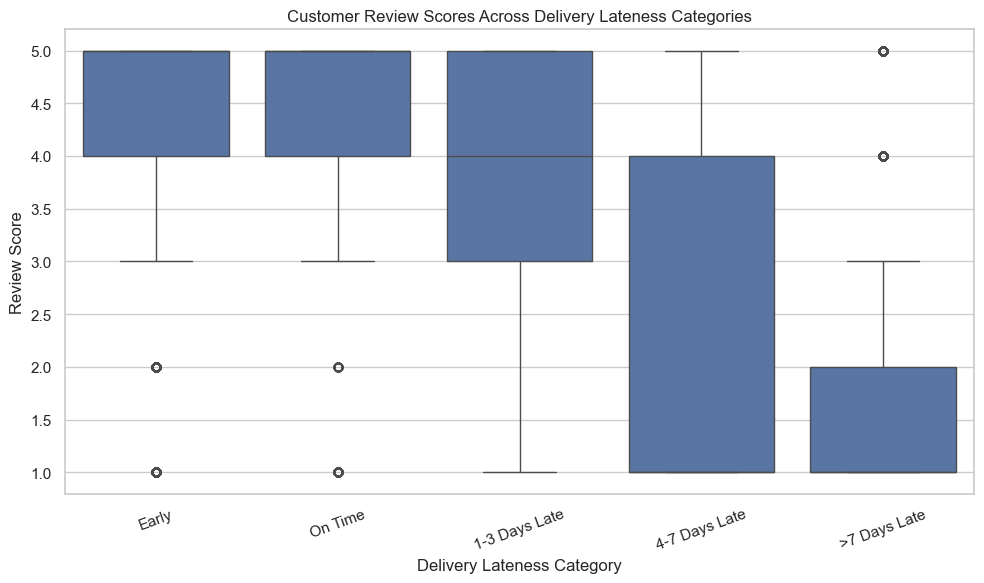

In [73]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=master_orders,
    x="lateness_bucket",
    y="review_score",
    order=bucket_order
)

plt.title("Customer Review Scores Across Delivery Lateness Categories")
plt.xlabel("Delivery Lateness Category")
plt.ylabel("Review Score")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

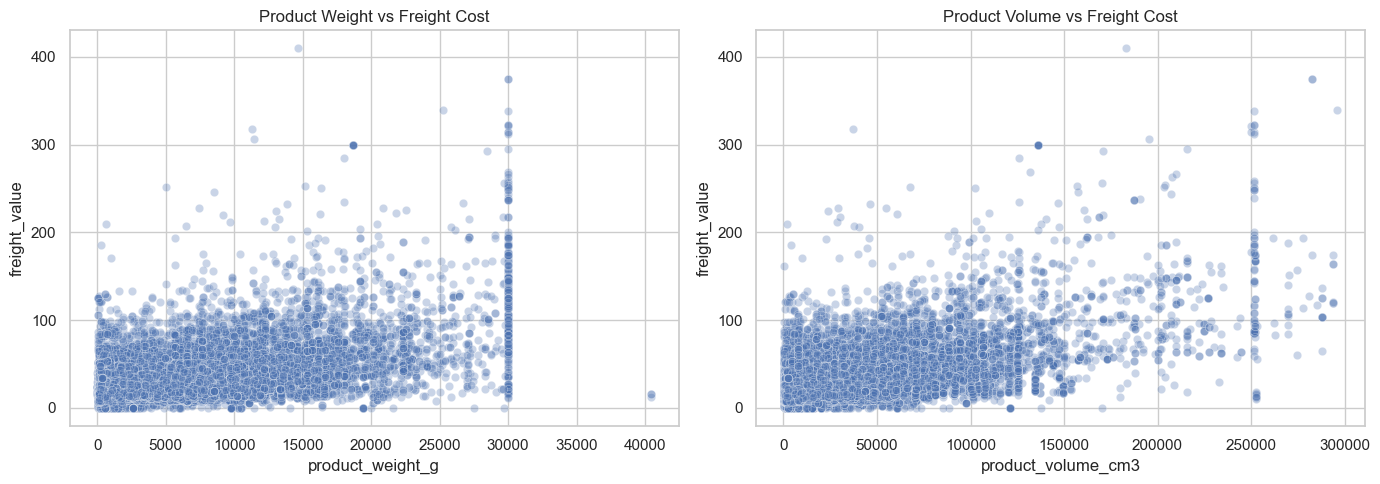

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=cleaned_items,
    x="product_weight_g",
    y="freight_value",
    alpha=0.3,
    ax=axes[0]
)

axes[0].set_title("Product Weight vs Freight Cost")

sns.scatterplot(
    data=cleaned_items,
    x="product_volume_cm3",
    y="freight_value",
    alpha=0.3,
    ax=axes[1]
)

axes[1].set_title("Product Volume vs Freight Cost")

plt.tight_layout()
plt.show()

### Observations – Bivariate Analysis

**1. Delivery Distance and Duration**

The Spearman correlation between distance and total delivery duration is 0.542, indicating a moderate positive association. This suggests that orders travelling longer distances generally take more time to reach customers.

**2. Delivery Performance and Customer Satisfaction**

The correlation between total delivery duration and review score is -0.235, indicating a negative association. Similarly, days late and review score have a Spearman correlation of -0.176.

**3. Lateness Categories and Review Scores**

The average review score decreases as delivery lateness increases. Early deliveries have an average rating of 4.30, whereas orders delayed by more than seven days have an average rating of 1.73. The decline becomes particularly noticeable in the 4–7 days late category, where the average rating falls to 2.32.

**4. Product Characteristics and Freight Cost**

Product weight and freight charges have a Spearman correlation of 0.447, while product volume and freight charges have a correlation of 0.369. This indicates that heavier and larger products tend to be associated with higher freight costs.

**5. Order Price and Freight Cost**

The correlation between product price and freight charges is 0.434, indicating a moderate positive association.

**Overall Conclusion**

The analysis suggests that delivery duration, distance and product characteristics are associated with important aspects of e-commerce performance. Most importantly, customer ratings decline considerably for orders experiencing longer delivery delays. These findings will be investigated further through formal hypothesis testing and effect size calculations.

## 2.4 Hypothesis Testing

### Purpose

Hypothesis testing is performed to determine whether the relationships observed during bivariate analysis are statistically significant.

In this project, hypothesis testing focuses on understanding the relationship between delivery delays and customer satisfaction. Three statistical tests are applied:

1. Mann–Whitney U Test
2. Kruskal–Wallis Test
3. Chi-Square Test

A significance level of 0.05 is used to evaluate the statistical results.

The tests help determine whether customer review scores differ between late and non-late orders, whether review scores vary across different lateness categories, and whether delivery lateness is associated with low customer ratings.

### 2.4.1 Data Preparation

The order-level dataset is prepared by selecting delivery lateness, customer review scores and lateness categories. Records with missing values in these variables are excluded from the hypothesis tests.

Orders are classified into two delivery groups: Late and Not Late. Customer reviews are also classified into Low Review (1–2 stars) and Other Review (3–5 stars).

In [75]:
hypothesis_data = master_orders[
    ["days_late", "review_score", "lateness_bucket"]
].copy()

hypothesis_data = hypothesis_data.dropna(
    subset=["days_late", "review_score", "lateness_bucket"]
)

hypothesis_data["delivery_status"] = np.where(
    hypothesis_data["days_late"] > 0,
    "Late",
    "Not Late"
)

hypothesis_data["low_review"] = np.where(
    hypothesis_data["review_score"] <= 2,
    "Low Review",
    "Other Review"
)

print("Dataset shape:", hypothesis_data.shape)
print(hypothesis_data.head())

Dataset shape: (95830, 5)
   days_late  review_score lateness_bucket delivery_status    low_review
0  -7.107488           4.0           Early        Not Late  Other Review
1  -5.355729           4.0           Early        Not Late  Other Review
2 -17.245498           5.0           Early        Not Late  Other Review
3 -12.980069           5.0           Early        Not Late  Other Review
4  -9.238171           5.0           Early        Not Late  Other Review


### 2.4.2 Mann–Whitney U Test

**Objective:** To determine whether customer review scores differ significantly between late and non-late orders.

**Hypotheses:**

- H₀ (Null Hypothesis): There is no significant difference in the distribution of customer review scores between late and non-late orders.
- H₁ (Alternative Hypothesis): There is a significant difference in the distribution of customer review scores between late and non-late orders.

The Mann–Whitney U test is used to compare the two independent groups.

In [76]:
not_late_scores = hypothesis_data.loc[
    hypothesis_data["delivery_status"] == "Not Late",
    "review_score"
]

late_scores = hypothesis_data.loc[
    hypothesis_data["delivery_status"] == "Late",
    "review_score"
]

u_statistic, p_value_mann = mannwhitneyu(
    not_late_scores,
    late_scores,
    alternative="two-sided"
)

print("MANN-WHITNEY U TEST")
print("-------------------")
print("U Statistic:", u_statistic)
print("P-value:", p_value_mann)
print("Not Late Median:", not_late_scores.median())
print("Late Median:", late_scores.median())

if p_value_mann < 0.05:
    print("Reject H0: Significant difference exists.")
else:
    print("Fail to reject H0: No significant difference found.")

MANN-WHITNEY U TEST
-------------------
U Statistic: 524744817.0
P-value: 0.0
Not Late Median: 5.0
Late Median: 2.0
Reject H0: Significant difference exists.


### 2.4.3 Kruskal–Wallis Test

**Objective:** To determine whether customer review scores differ significantly across the five delivery lateness categories.

**Hypotheses:**

- H₀ (Null Hypothesis): The distribution of review scores is the same across all lateness categories.
- H₁ (Alternative Hypothesis): At least one lateness category has a different review score distribution.

The Kruskal–Wallis test is a non-parametric method used to compare three or more independent groups.

In [77]:
bucket_order = [
    "Early",
    "On Time",
    "1-3 Days Late",
    "4-7 Days Late",
    ">7 Days Late"
]

groups = [
    hypothesis_data.loc[
        hypothesis_data["lateness_bucket"] == bucket,
        "review_score"
    ].dropna()
    for bucket in bucket_order
]

# Remove empty groups if any
groups = [group for group in groups if len(group) > 0]

h_statistic, p_value = kruskal(*groups)

print("KRUSKAL-WALLIS TEST")
print("-------------------")
print("H Statistic:", h_statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("Result: At least one lateness category has a significantly different review score distribution.")
else:
    print("Result: No statistically significant difference between the categories.")

KRUSKAL-WALLIS TEST
-------------------
H Statistic: 10154.079907772195
P-value: 0.0
Result: At least one lateness category has a significantly different review score distribution.


### 2.4.4 Chi-Square Test of Independence

**Objective:** To determine whether delivery lateness categories are associated with low customer review scores (1–2 stars).

**Hypotheses:**

- H₀ (Null Hypothesis): Delivery lateness category and low review status are independent.
- H₁ (Alternative Hypothesis): Delivery lateness category and low review status are associated.

The Chi-Square Test of Independence is used to examine the association between two categorical variables.

In [78]:
contingency_table = pd.crosstab(
    hypothesis_data["lateness_bucket"],
    hypothesis_data["low_review"]
)

print("CONTINGENCY TABLE")
display(contingency_table)

chi2_statistic, p_value, degrees_freedom, expected_frequencies = (
    chi2_contingency(contingency_table)
)

print("\nCHI-SQUARE TEST")
print("----------------")
print("Chi-square Statistic:", chi2_statistic)
print("Degrees of Freedom:", degrees_freedom)
print("P-value:", p_value)

if p_value < 0.05:
    print("Result: Delivery lateness category and low review status are significantly associated.")
else:
    print("Result: No statistically significant association was found.")

CONTINGENCY TABLE


low_review,Low Review,Other Review
lateness_bucket,,
1-3 Days Late,504,2132
4-7 Days Late,1086,687
>7 Days Late,2551,702
Early,7974,78744
On Time,160,1290



CHI-SQUARE TEST
----------------
Chi-square Statistic: 17376.01099547231
Degrees of Freedom: 4
P-value: 0.0
Result: Delivery lateness category and low review status are significantly associated.


### 2.4.5 Comparison of Hypothesis Testing Results

The results of the three statistical tests are consolidated to compare their test statistics and p-values. A significance level of 0.05 is used to determine whether the null hypotheses can be rejected.

### 2.4.6 Conclusion

The three hypothesis tests indicate statistically significant relationships between delivery performance and customer satisfaction.

The Mann–Whitney U test identified a significant difference in review score distributions between late and non-late orders. The median review score was 5 for non-late orders and 2 for late orders.

The Kruskal–Wallis test indicated significant differences in review score distributions across the five lateness categories. The Chi-Square test also identified a significant association between delivery lateness categories and low customer review status.

These findings provide statistical evidence that delivery lateness is associated with customer satisfaction. However, statistical significance alone does not indicate the practical strength of these relationships. Therefore, effect size calculations are required in the next section.

## 2.5 Effect Size Calculations

### Purpose

Effect size calculations measure the magnitude of relationships or differences identified through hypothesis testing.

While p-values indicate whether a result is statistically significant, effect sizes help determine whether the observed difference or association is practically meaningful.

In this project, two effect size measures are used:

1. **Cliff's Delta:** Measures the magnitude and direction of the difference in customer review scores between late and non-late orders.
2. **Cramér's V:** Measures the strength of association between delivery lateness categories and low customer review status.

These measures complement the hypothesis testing results and provide a better understanding of the relationship between delivery performance and customer satisfaction.

### 2.5.1 Cliff's Delta

Cliff's Delta is a non-parametric effect size measure used to compare two independent groups. It measures the probability that a randomly selected observation from one group is greater than an observation from the other group, adjusted for ties.

In this project, it is used to compare customer review scores between late and non-late orders.

The value ranges from -1 to +1:

- A negative value indicates that late orders generally have lower review scores.
- A positive value indicates that late orders generally have higher review scores.
- A value close to zero indicates little difference between the groups.

In [79]:
# Calculate Cliff's Delta using the Mann-Whitney U statistic

n_late = len(late_scores)
n_not_late = len(not_late_scores)

# Calculate U with late orders as the first group
u_late, _ = mannwhitneyu(
    late_scores,
    not_late_scores,
    alternative="two-sided"
)

cliffs_delta = (
    (2 * u_late) / (n_late * n_not_late)
) - 1

print("CLIFF'S DELTA")
print("-------------")
print("Late orders:", n_late)
print("Non-late orders:", n_not_late)
print("Cliff's Delta:", cliffs_delta)

CLIFF'S DELTA
-------------
Late orders: 7662
Non-late orders: 88168
Cliff's Delta: -0.5535492166055591


In [80]:
abs_delta = abs(cliffs_delta)

if abs_delta < 0.147:
    delta_interpretation = "Negligible effect"
elif abs_delta < 0.33:
    delta_interpretation = "Small effect"
elif abs_delta < 0.474:
    delta_interpretation = "Medium effect"
else:
    delta_interpretation = "Large effect"

print("Effect Size Interpretation:", delta_interpretation)

if cliffs_delta < 0:
    print("Direction: Late orders tend to have lower review scores.")
elif cliffs_delta > 0:
    print("Direction: Late orders tend to have higher review scores.")
else:
    print("Direction: No difference between the groups.")

Effect Size Interpretation: Large effect
Direction: Late orders tend to have lower review scores.


### 2.5.2 Cramér's V

Cramér's V is an effect size measure used to determine the strength of association between two categorical variables.

In this project, it measures the association between delivery lateness categories and customer review status (Low Review or Other Review).

The value ranges from 0 to 1:

- A value close to 0 indicates a weak association.
- A value closer to 1 indicates a stronger association.

Cramér's V complements the Chi-Square test by measuring the strength of the observed association rather than only its statistical significance.

In [81]:
# Calculate Cramér's V using the Chi-Square result

chi2_value = chi2_statistic

n = contingency_table.to_numpy().sum()

rows, cols = contingency_table.shape

minimum_dimension = min(rows - 1, cols - 1)

cramers_v = np.sqrt(
    chi2_value / (n * minimum_dimension)
)

print("CRAMER'S V")
print("----------")
print("Chi-Square Statistic:", chi2_value)
print("Total Observations:", n)
print("Cramer's V:", cramers_v)

CRAMER'S V
----------
Chi-Square Statistic: 17376.01099547231
Total Observations: 95830
Cramer's V: 0.4258182759917095


In [82]:
effect_size_results = pd.DataFrame([
    {
        "Effect Size": "Cliff's Delta",
        "Value": cliffs_delta,
        "Interpretation": delta_interpretation
    },
    {
        "Effect Size": "Cramer's V",
        "Value": cramers_v,
        "Interpretation": (
            "Strength of association between lateness "
            "category and low review status"
        )
    }
])

display(effect_size_results)

,Effect Size,Value,Interpretation
0,Cliff's Delta,-0.553549,Large effect
1,Cramer's V,0.425818,Strength of association between lateness categ...


### 2.5.3 Observations

**1. Cliff's Delta**

The calculated Cliff's Delta is -0.554, indicating a large effect. The negative value shows that late orders tend to receive lower customer review scores compared with non-late orders. This demonstrates a substantial difference in customer satisfaction between the two delivery groups.

**2. Cramér's V**

The calculated Cramér's V is 0.426, indicating a moderate-to-strong association between delivery lateness categories and low customer review status. This suggests that delivery performance is meaningfully associated with the likelihood of receiving a low customer rating.

**Overall Observation**

Both effect size measures indicate that delivery delays are not only statistically significant but also associated with practically meaningful differences in customer satisfaction.

### 2.5.4 Conclusion

The effect size analysis provides evidence that delivery delays are meaningfully associated with customer satisfaction.

Cliff's Delta indicates a large difference in review scores between late and non-late orders, with late orders generally receiving lower ratings. Cramér's V also indicates a moderate-to-strong association between lateness categories and low customer reviews.

These findings complement the hypothesis testing results and highlight the importance of timely delivery in maintaining customer satisfaction in the Olist e-commerce platform.

## 2.6 Numerical Transformations

### Purpose

Numerical transformations are applied to improve the distribution and scale of numerical variables. Several variables in the Olist dataset exhibit skewness and extreme values, which can affect statistical analysis and machine learning algorithms.

In this section, different transformation techniques are applied to selected numerical variables to examine how they change the distribution of the data.

The following techniques are implemented:

1. **Log Transformation:** Reduces right skewness in non-negative numerical variables.
2. **Square Root Transformation:** Reduces moderate right skewness.
3. **Box-Cox Transformation:** Uses a power transformation to make strictly positive data more symmetric.
4. **Yeo-Johnson Transformation:** Handles both positive and negative values while reducing skewness.
5. **Feature Scaling:** Applies Standard Scaling, Robust Scaling and Min-Max Scaling to bring numerical variables onto comparable scales.

The transformed distributions are compared with the original distributions using skewness values and visualizations.

### 2.6.1 Selection of Numerical Variables

Numerical variables are selected from the order, seller and item datasets based on their relevance to delivery performance, transaction value and product characteristics.

The selected variables include order value, freight charges, delivery duration, delivery lateness, seller revenue and product characteristics.

These variables are used to examine the effectiveness of different numerical transformation techniques.

In [83]:
# Select numerical variables for transformations

# Variables suitable for Log, Square Root and Box-Cox transformations
transformation_data = {
    "Orders": master_orders[
        ["total_price", "total_freight", "total_delivery_days"]
    ],

    "Sellers": master_sellers[
        ["total_revenue"]
    ],

    "Items": cleaned_items[
        ["price", "freight_value"]
    ]
}

# Keep days_late separately because it contains negative values
# representing orders delivered earlier than estimated
days_late_data = master_orders[["days_late"]].copy()

# Display descriptive statistics
for dataset_name, df in transformation_data.items():
    print(f"\n{dataset_name}")
    display(df.describe())

print("\nOrders - Days Late")
display(days_late_data.describe())


Orders


,total_price,total_freight,total_delivery_days
count,98666.000000,98666.000000,96476.000000
mean,137.754076,22.823562,12.558702
std,210.645145,21.650909,9.546530
min,0.850000,0.000000,0.533414
25%,45.900000,13.850000,6.766403
50%,86.900000,17.170000,10.217755
75%,149.900000,24.040000,15.720327
max,13440.000000,1794.960000,209.628611



Sellers


,total_revenue
count,3095.000000
mean,4391.484233
std,13921.997192
min,3.500000
25%,208.850000
50%,821.480000
75%,3280.830000
max,229472.630000



Items


,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000



Orders - Days Late


,days_late
count,96476.000000
mean,-11.179120
std,10.186113
min,-146.016123
25%,-16.244384
50%,-11.948941
75%,-6.390000
max,188.975081


### 2.6.2 Log Transformation

Log transformation is used to reduce right skewness in numerical variables by compressing large values more than smaller values.

The log1p transformation, calculated as log(1 + x), is used because it can also handle zero values.

In this project, log transformation is applied to non-negative variables such as order value, freight charges, seller revenue and product price.

The original and transformed distributions are compared to evaluate changes in skewness.

In [84]:
# Apply Log Transformation

log_results = {}

for dataset_name, df in transformation_data.items():
    for column in df.columns:

        values = df[column].dropna()

        # Log transformation requires non-negative values
        values = values[values >= 0]

        if len(values) > 0:
            transformed = np.log1p(values)

            log_results[f"{dataset_name}_{column}"] = {
                "Original": values,
                "Transformed": transformed
            }

            print(
                f"{dataset_name} - {column}: "
                f"Original Skewness = {values.skew():.4f}, "
                f"Log Skewness = {transformed.skew():.4f}"
            )

Orders - total_price: Original Skewness = 9.7277, Log Skewness = 0.2881
Orders - total_freight: Original Skewness = 12.0527, Log Skewness = 0.4707
Orders - total_delivery_days: Original Skewness = 3.8328, Log Skewness = 0.0353
Sellers - total_revenue: Original Skewness = 9.0481, Log Skewness = 0.1129
Items - price: Original Skewness = 7.9232, Log Skewness = 0.2935
Items - freight_value: Original Skewness = 5.6399, Log Skewness = 0.0011


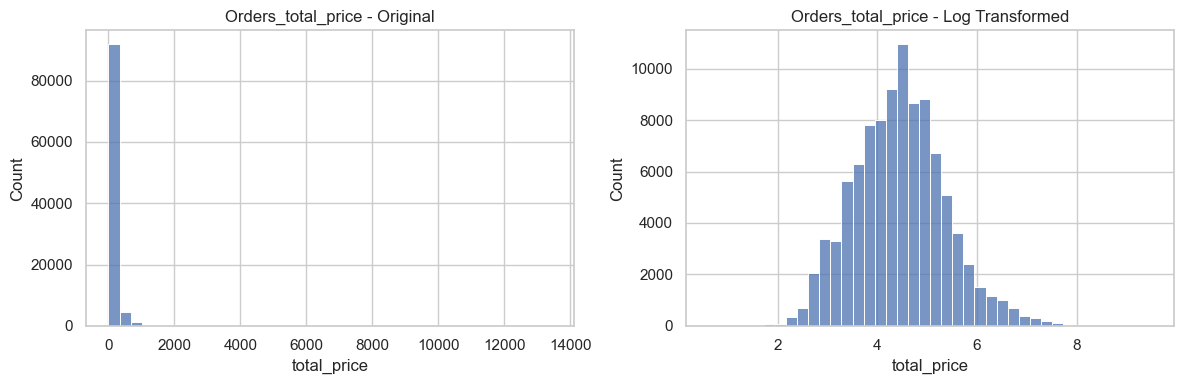

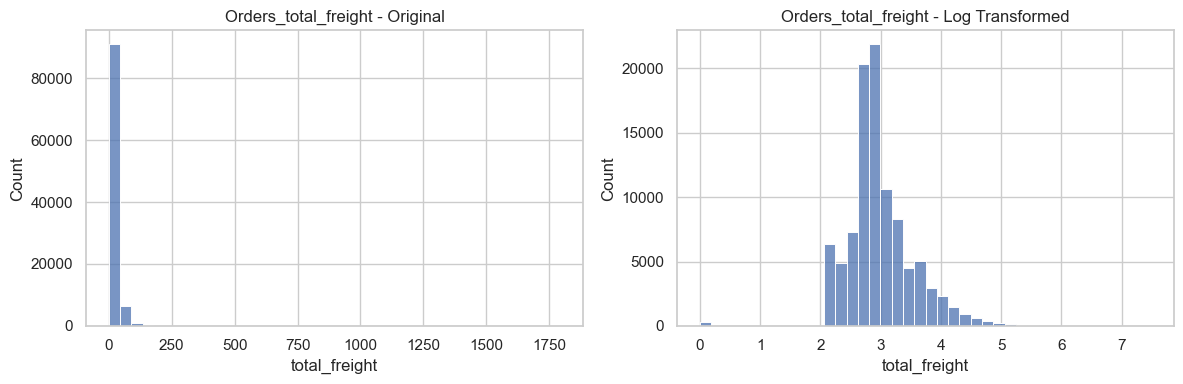

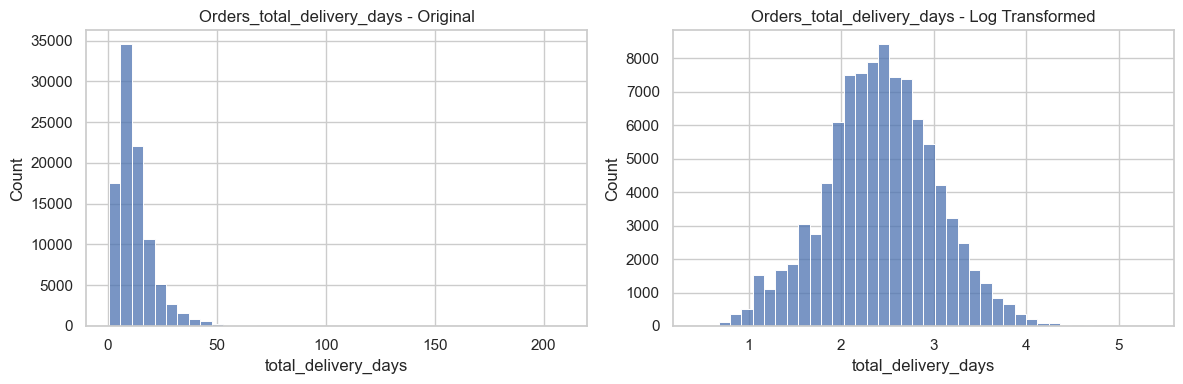

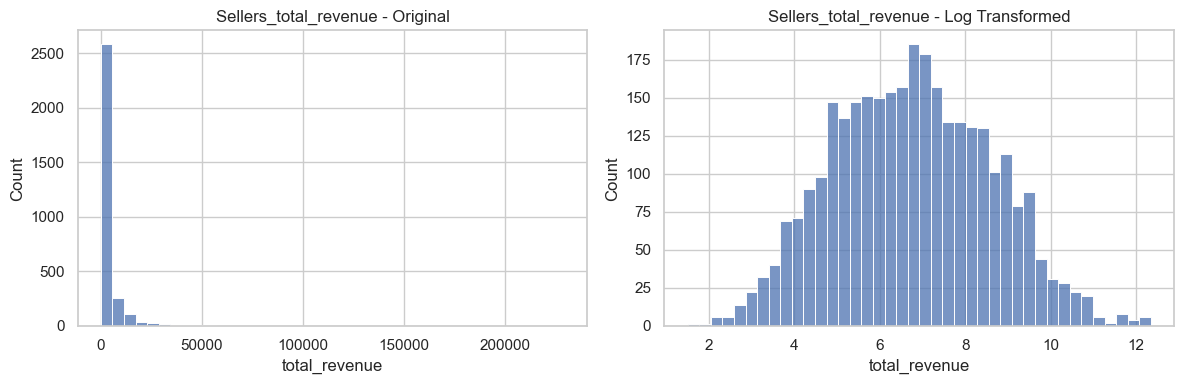

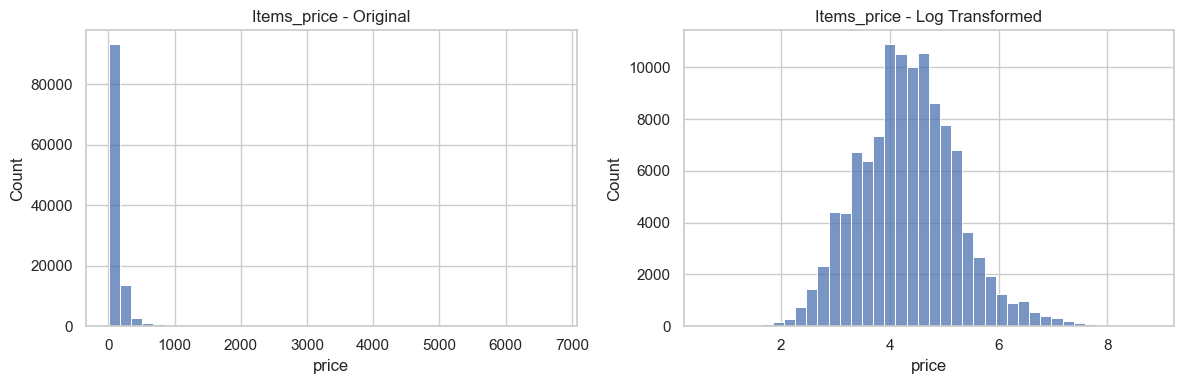

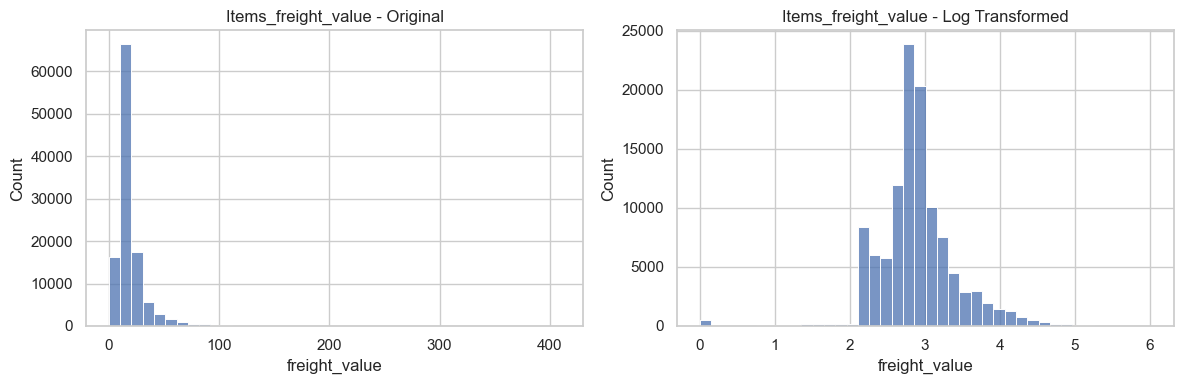

In [85]:
for variable, result in log_results.items():

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(
        result["Original"],
        bins=40,
        ax=axes[0]
    )
    axes[0].set_title(f"{variable} - Original")

    sns.histplot(
        result["Transformed"],
        bins=40,
        ax=axes[1]
    )
    axes[1].set_title(f"{variable} - Log Transformed")

    plt.tight_layout()
    plt.show()

### 2.6.3 Square Root Transformation

Square root transformation is another method used to reduce right skewness in numerical variables.

It is less aggressive than logarithmic transformation and is suitable for non-negative numerical values.

The transformation is calculated using the square root of each observation.

In this project, it is applied to selected non-negative variables, and the resulting distributions are compared with their original distributions using skewness values and histograms.

In [86]:
# Apply Square Root Transformation

sqrt_results = {}

for dataset_name, df in transformation_data.items():
    for column in df.columns:

        values = df[column].dropna()
        values = values[values >= 0]

        if len(values) > 0:
            transformed = np.sqrt(values)

            sqrt_results[f"{dataset_name}_{column}"] = {
                "Original": values,
                "Transformed": transformed
            }

            print(
                f"{dataset_name} - {column}: "
                f"Original Skewness = {values.skew():.4f}, "
                f"Sqrt Skewness = {transformed.skew():.4f}"
            )

Orders - total_price: Original Skewness = 9.7277, Sqrt Skewness = 2.4776
Orders - total_freight: Original Skewness = 12.0527, Sqrt Skewness = 2.6034
Orders - total_delivery_days: Original Skewness = 3.8328, Sqrt Skewness = 1.1065
Sellers - total_revenue: Original Skewness = 9.0481, Sqrt Skewness = 3.2659
Items - price: Original Skewness = 7.9232, Sqrt Skewness = 2.5209
Items - freight_value: Original Skewness = 5.6399, Sqrt Skewness = 2.1737


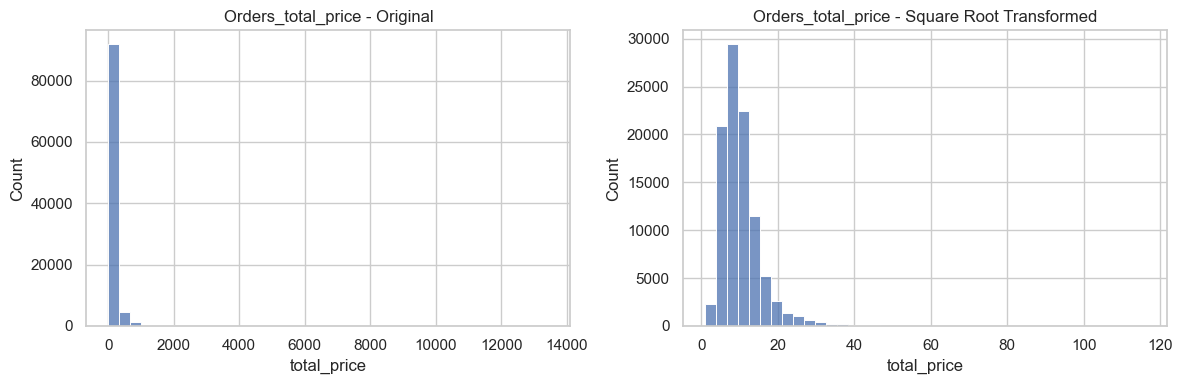

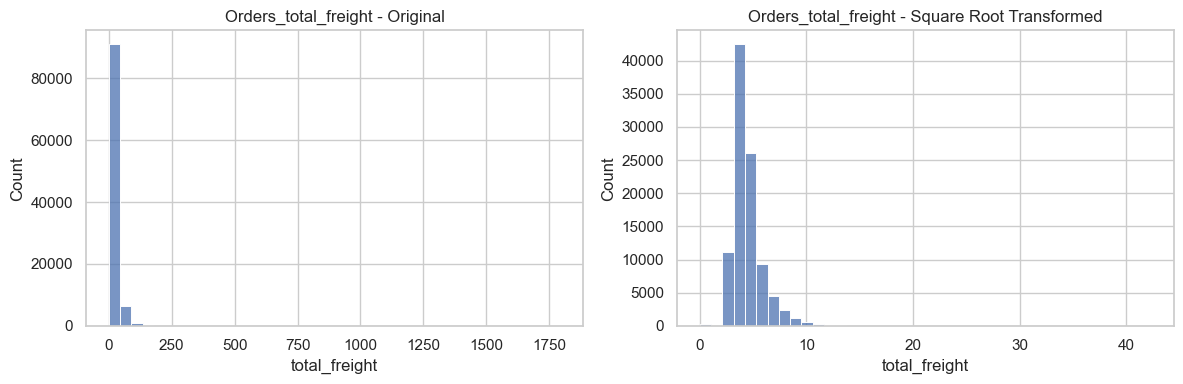

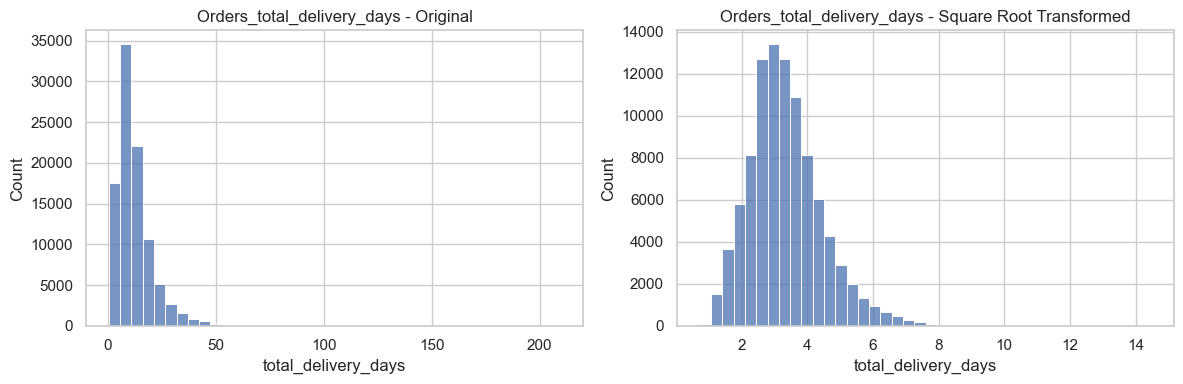

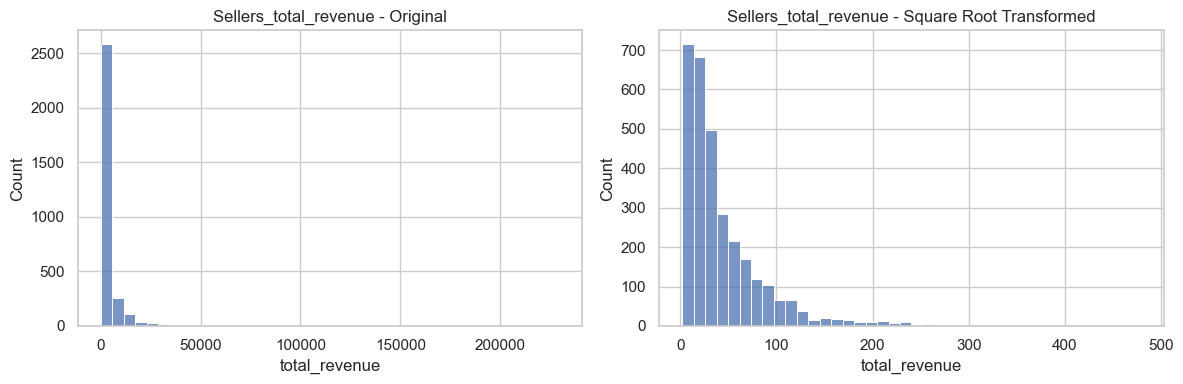

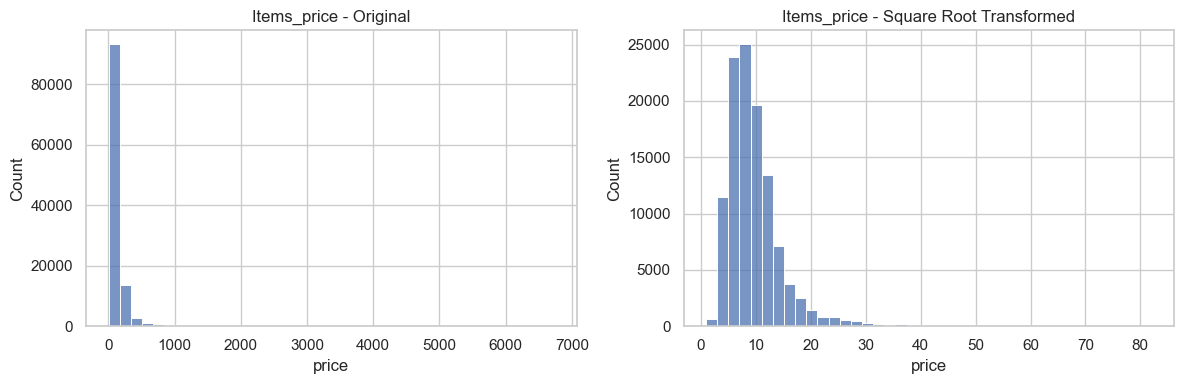

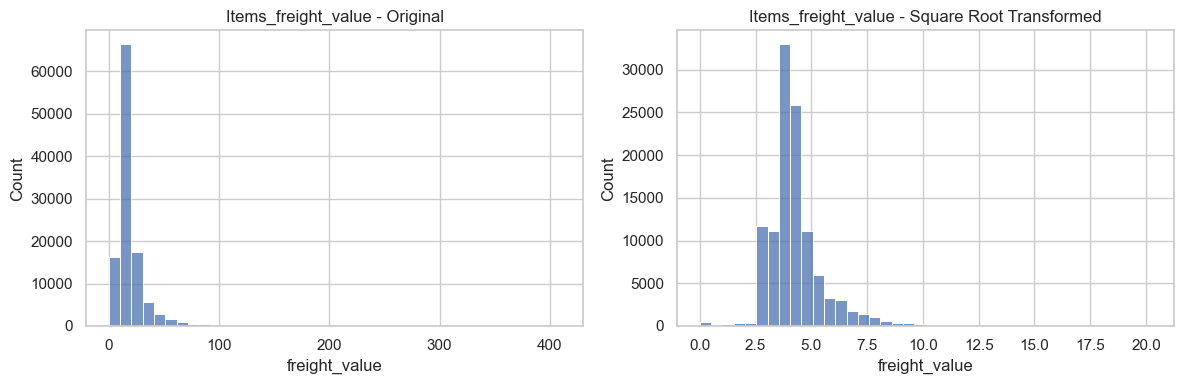

In [87]:
for variable, result in sqrt_results.items():

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(
        result["Original"],
        bins=40,
        ax=axes[0]
    )
    axes[0].set_title(f"{variable} - Original")

    sns.histplot(
        result["Transformed"],
        bins=40,
        ax=axes[1]
    )
    axes[1].set_title(f"{variable} - Square Root Transformed")

    plt.tight_layout()
    plt.show()

### 2.6.4 Box-Cox Transformation

Box-Cox transformation is a power transformation technique used to reduce skewness and make numerical data more symmetric.

It requires strictly positive values. Therefore, variables containing zero or negative values cannot be directly used without an appropriate adjustment.

In this project, Box-Cox transformation is applied to selected strictly positive variables, including order value, freight charges, seller revenue and product price.

The transformation parameter (lambda) is estimated from the data.

In [88]:
from scipy.stats import boxcox

# Apply Box-Cox Transformation

boxcox_results = {}

for dataset_name, df in transformation_data.items():
    for column in df.columns:

        values = df[column].dropna()

        # Box-Cox requires strictly positive values
        values = values[values > 0]

        if len(values) > 1 and values.nunique() > 1:

            transformed, lambda_value = boxcox(values)

            transformed = pd.Series(
                transformed,
                index=values.index
            )

            boxcox_results[f"{dataset_name}_{column}"] = {
                "Original": values,
                "Transformed": transformed,
                "Lambda": lambda_value
            }

            print(f"\n{dataset_name} - {column}")
            print("Lambda:", lambda_value)
            print("Original Skewness:", values.skew())
            print("Box-Cox Skewness:", transformed.skew())


Orders - total_price
Lambda: -0.0805288494410356
Original Skewness: 9.72774072310121
Box-Cox Skewness: -0.004215833614820452

Orders - total_freight
Lambda: -0.526293060872225
Original Skewness: 12.0944905993979
Box-Cox Skewness: -0.0008111773253606925

Orders - total_delivery_days
Lambda: 0.09003912064266664
Original Skewness: 3.832816705237246
Box-Cox Skewness: 0.00637144351362575

Sellers - total_revenue
Lambda: -0.02139235606053827
Original Skewness: 9.048144726211095
Box-Cox Skewness: 0.0057879883423171226

Items - price
Lambda: -0.0751358598677465
Original Skewness: 7.92320826321351
Box-Cox Skewness: -0.00785263004471574

Items - freight_value
Lambda: 0.0514245481072181
Original Skewness: 5.670639172601192
Box-Cox Skewness: 0.07987325358654018


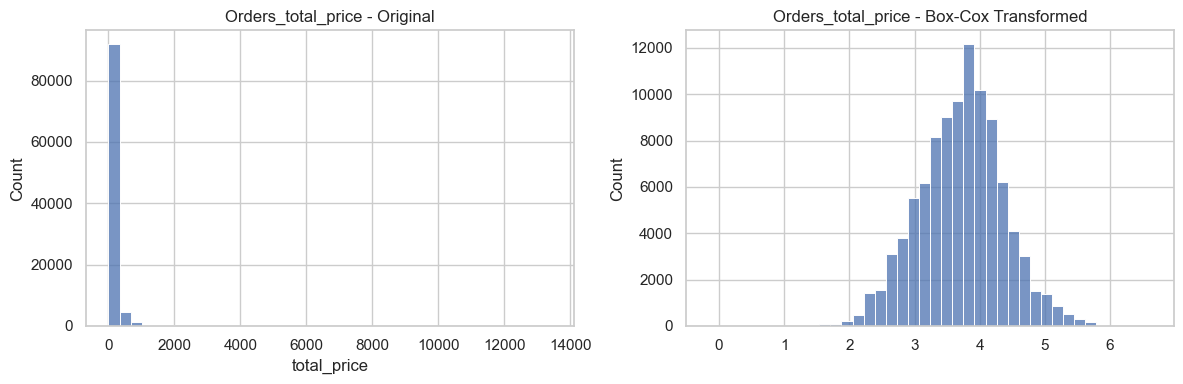

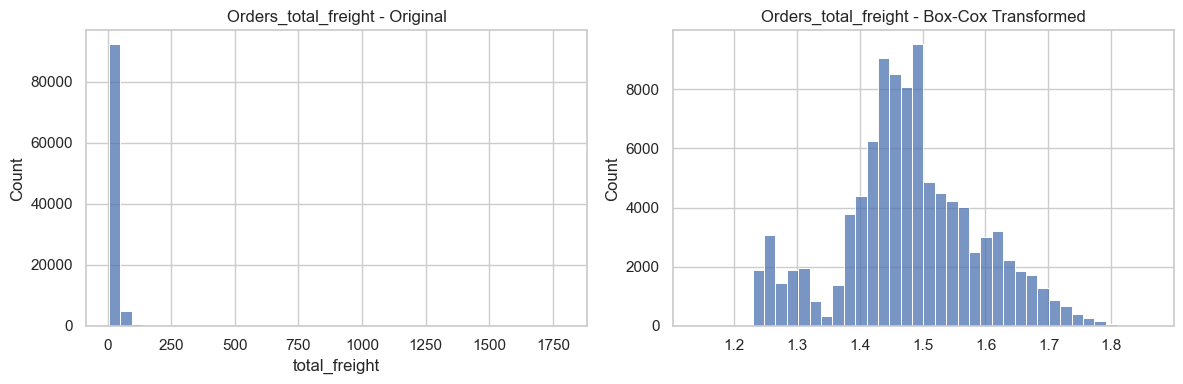

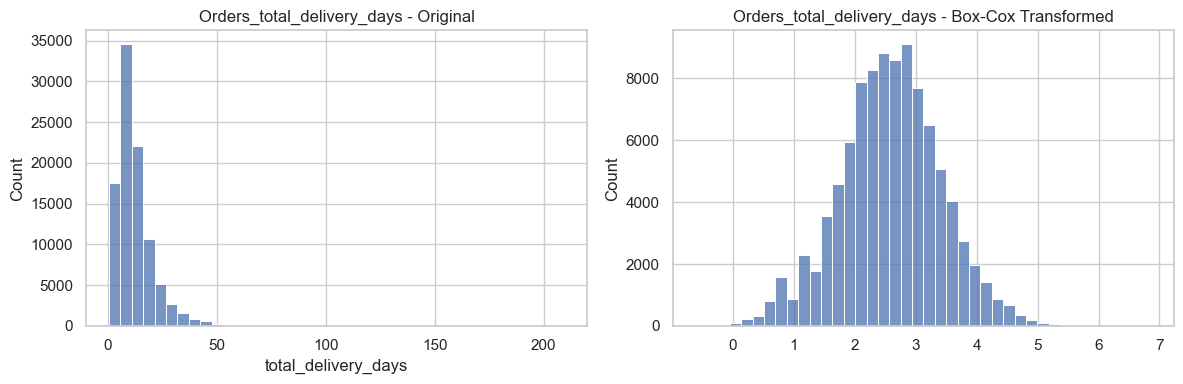

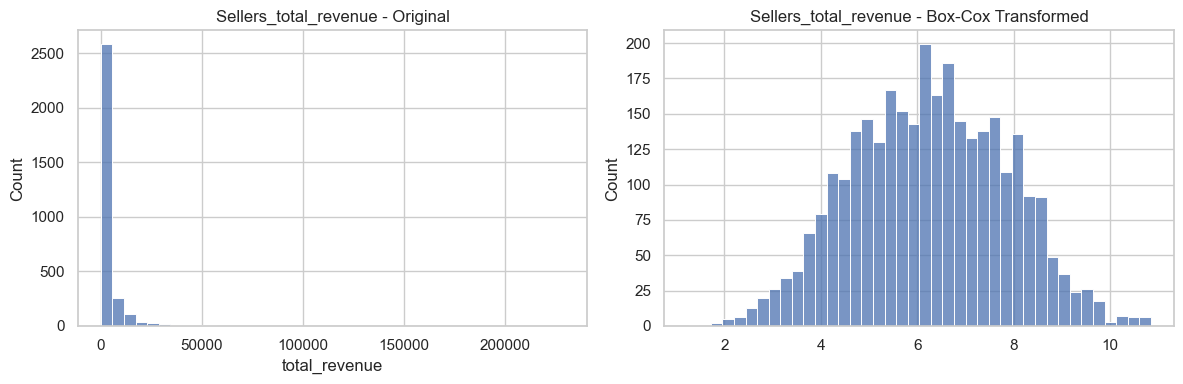

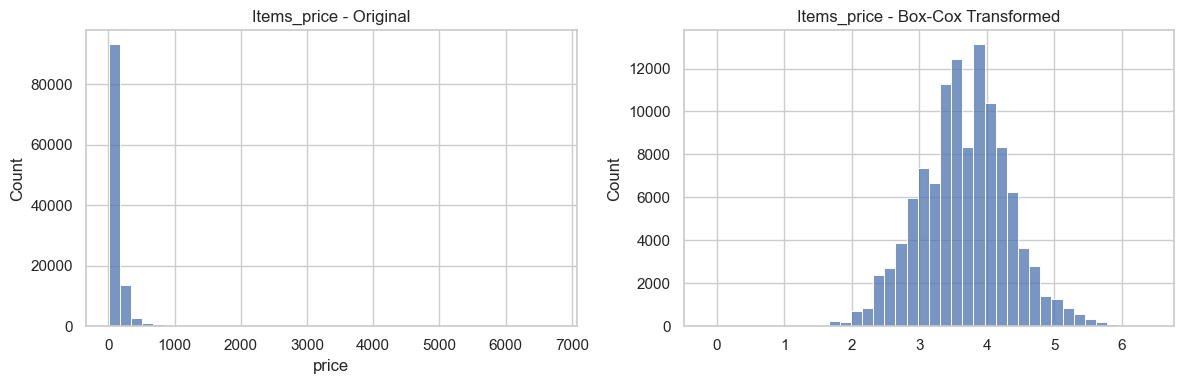

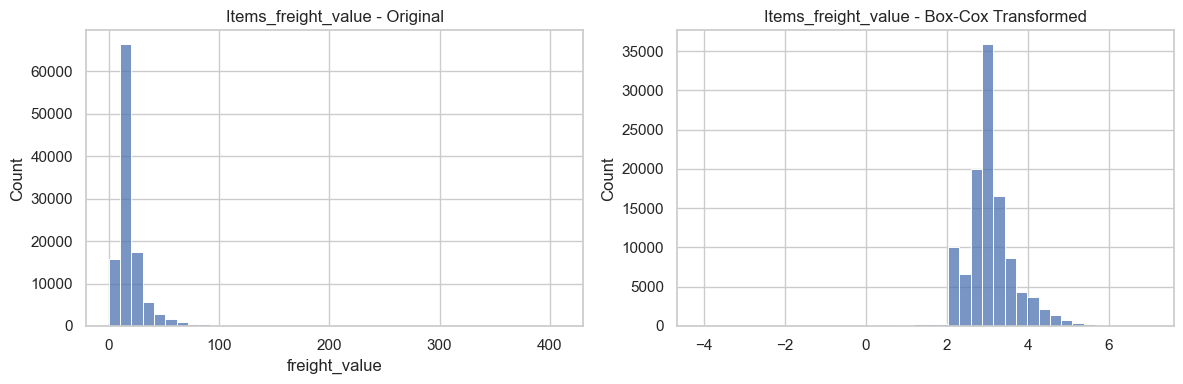

In [89]:
for variable, result in boxcox_results.items():

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(
        result["Original"],
        bins=40,
        ax=axes[0]
    )
    axes[0].set_title(f"{variable} - Original")

    sns.histplot(
        result["Transformed"],
        bins=40,
        ax=axes[1]
    )
    axes[1].set_title(f"{variable} - Box-Cox Transformed")

    plt.tight_layout()
    plt.show()

### 2.6.5 Yeo-Johnson Transformation

Yeo-Johnson transformation is a power transformation technique that can handle positive, zero and negative numerical values.

Unlike Box-Cox transformation, it does not require all observations to be strictly positive.

In this project, Yeo-Johnson transformation is particularly useful for variables such as days_late, which contains negative values representing early deliveries and positive values representing late deliveries.

It is also applied to other selected numerical variables to examine changes in their distributions.

In [90]:
from sklearn.preprocessing import PowerTransformer

# Include all selected numerical variables and days_late
yeojohnson_data = {
    **transformation_data,
    "Orders_Lateness": days_late_data
}

# Apply Yeo-Johnson Transformation
yeojohnson_results = {}

for dataset_name, df in yeojohnson_data.items():
    for column in df.columns:

        values = df[column].dropna()

        if len(values) > 1 and values.nunique() > 1:

            transformer = PowerTransformer(
                method="yeo-johnson",
                standardize=False
            )

            transformed_array = transformer.fit_transform(
                values.to_numpy().reshape(-1, 1)
            ).flatten()

            transformed = pd.Series(
                transformed_array,
                index=values.index
            )

            yeojohnson_results[f"{dataset_name}_{column}"] = {
                "Original": values,
                "Transformed": transformed,
                "Lambda": transformer.lambdas_[0]
            }

            print(f"\n{dataset_name} - {column}")
            print("Lambda:", transformer.lambdas_[0])
            print("Original Skewness:", values.skew())
            print("Yeo-Johnson Skewness:", transformed.skew())


Orders - total_price
Lambda: -0.09733756646101205
Original Skewness: 9.72774072310121
Yeo-Johnson Skewness: -0.003163658269737617

Orders - total_freight
Lambda: -0.1046197832814178
Original Skewness: 12.052722636430127
Yeo-Johnson Skewness: -0.09952247498215411

Orders - total_delivery_days
Lambda: -0.01834357504447513
Original Skewness: 3.832816705237246
Yeo-Johnson Skewness: -0.0005597742864354254

Sellers - total_revenue
Lambda: -0.024746645452137946
Original Skewness: 9.048144726211095
Yeo-Johnson Skewness: 0.007011376780803654

Items - price
Lambda: -0.09658480315230246
Original Skewness: 7.92320826321351
Yeo-Johnson Skewness: -0.006516480440585491

Items - freight_value
Lambda: -0.0002318847478706142
Original Skewness: 5.639869620428684
Yeo-Johnson Skewness: -0.00021275295691912534

Orders_Lateness - days_late
Lambda: 0.8490351882505708
Original Skewness: 2.0091981000059222
Yeo-Johnson Skewness: -0.7580033764240105


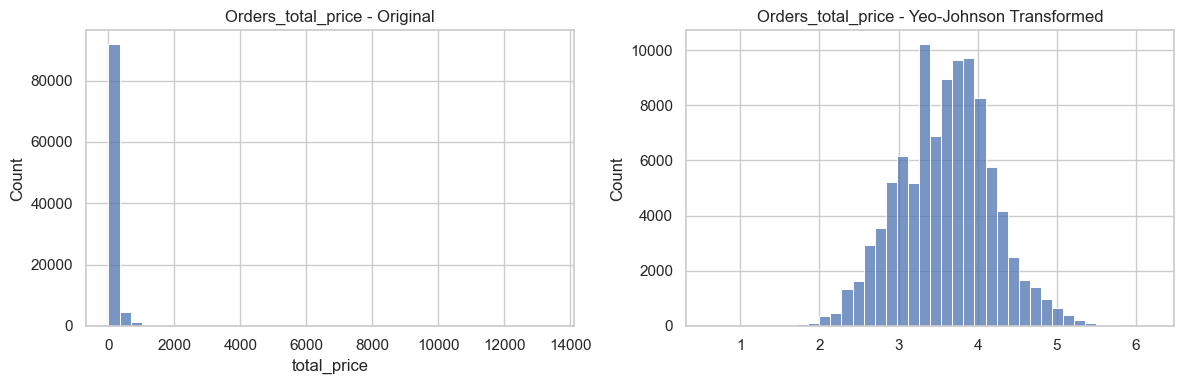

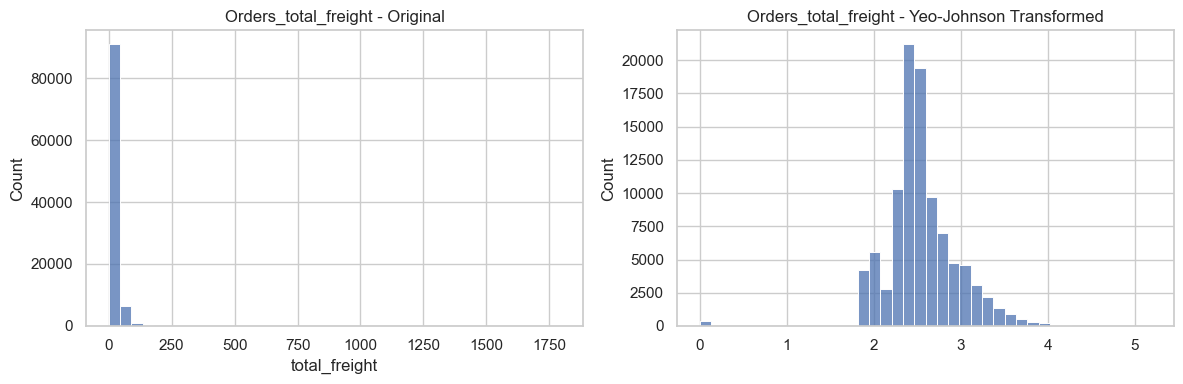

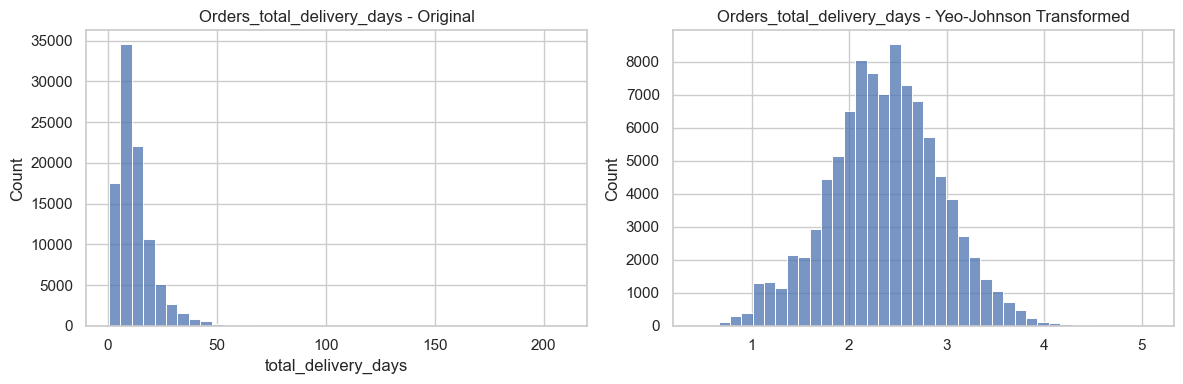

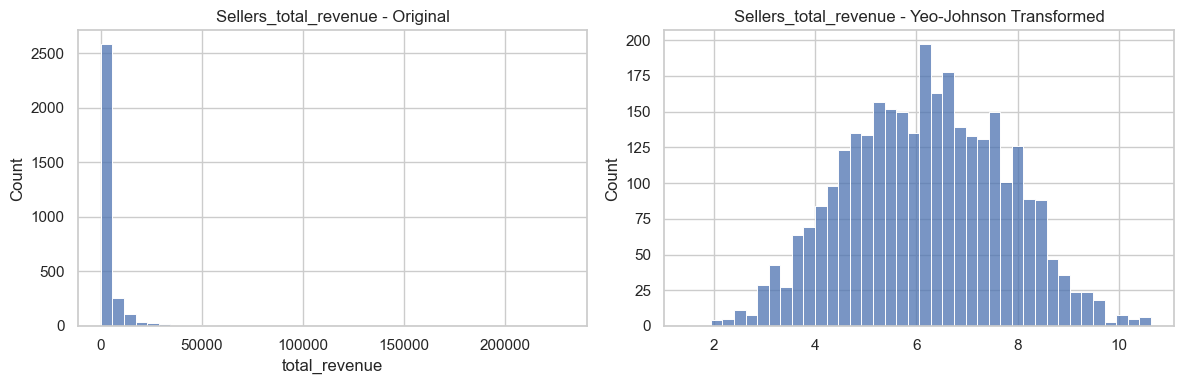

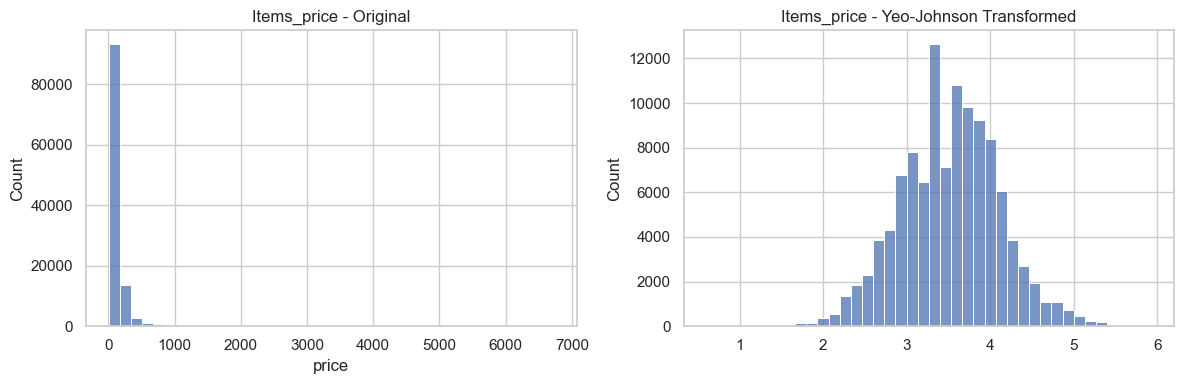

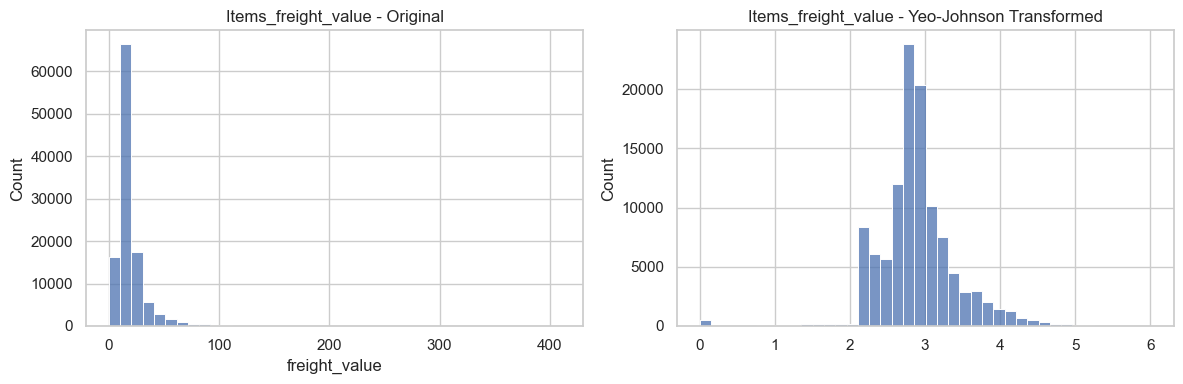

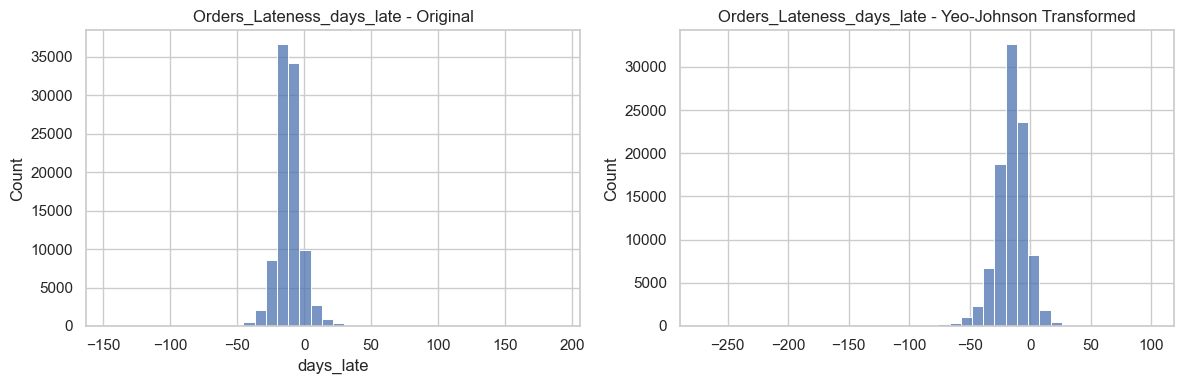

In [91]:
for variable, result in yeojohnson_results.items():

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(
        result["Original"],
        bins=40,
        ax=axes[0]
    )
    axes[0].set_title(f"{variable} - Original")

    sns.histplot(
        result["Transformed"],
        bins=40,
        ax=axes[1]
    )
    axes[1].set_title(f"{variable} - Yeo-Johnson Transformed")

    plt.tight_layout()
    plt.show()

### 2.6.6 Comparison of Transformation Techniques

The effectiveness of the different transformation techniques is evaluated by comparing the skewness of the original and transformed variables.

The comparison includes Log, Square Root, Box-Cox and Yeo-Johnson transformations.

A reduction in the absolute skewness value indicates that the transformed distribution has become more symmetric.

The results are compared to identify which transformation is more suitable for each numerical variable.

In [92]:
comparison_results = []

all_results = {
    "Log": log_results,
    "Square Root": sqrt_results,
    "Box-Cox": boxcox_results,
    "Yeo-Johnson": yeojohnson_results
}

for method, results in all_results.items():

    for variable, result in results.items():

        comparison_results.append({
            "Variable": variable,
            "Transformation": method,
            "Original Skewness": result["Original"].skew(),
            "Transformed Skewness": result["Transformed"].skew(),
            "Absolute Skewness Before": abs(
                result["Original"].skew()
            ),
            "Absolute Skewness After": abs(
                result["Transformed"].skew()
            )
        })

transformation_comparison = pd.DataFrame(
    comparison_results
)

display(
    transformation_comparison.sort_values(
        by="Absolute Skewness After"
    )
)

,Variable,Transformation,Original Skewness,Transformed Skewness,Absolute Skewness Before,Absolute Skewness After
23,Items_freight_value,Yeo-Johnson,5.639870,-0.000213,5.639870,0.000213
20,Orders_total_delivery_days,Yeo-Johnson,3.832817,-0.000560,3.832817,0.000560
13,Orders_total_freight,Box-Cox,12.094491,-0.000811,12.094491,0.000811
5,Items_freight_value,Log,5.639870,0.001111,5.639870,0.001111
18,Orders_total_price,Yeo-Johnson,9.727741,-0.003164,9.727741,0.003164
12,Orders_total_price,Box-Cox,9.727741,-0.004216,9.727741,0.004216
15,Sellers_total_revenue,Box-Cox,9.048145,0.005788,9.048145,0.005788
14,Orders_total_delivery_days,Box-Cox,3.832817,0.006371,3.832817,0.006371
22,Items_price,Yeo-Johnson,7.923208,-0.006516,7.923208,0.006516
21,Sellers_total_revenue,Yeo-Johnson,9.048145,0.007011,9.048145,0.007011


### 2.6.7 Feature Scaling

Feature scaling is used to bring numerical variables onto comparable scales.

Variables in the Olist dataset have different measurement units and ranges. For example, order revenue, delivery duration and freight charges have considerably different numerical scales.

Three scaling techniques are implemented:

1. **Standard Scaling:** Transforms variables to have a mean of approximately zero and a standard deviation of approximately one.
2. **Robust Scaling:** Uses the median and interquartile range, making it less sensitive to extreme values.
3. **Min-Max Scaling:** Rescales values to a range between zero and one.

The three methods are compared using selected numerical variables from the seller dataset.

In [93]:
from sklearn.preprocessing import (
    StandardScaler,
    RobustScaler,
    MinMaxScaler
)

# Select seller performance features

scaling_columns = [
    "total_orders",
    "total_revenue",
    "avg_handling_days",
    "avg_transit_days",
    "avg_delivery_days",
    "late_rate",
    "avg_review_score",
    "avg_distance_km"
]

scaling_data = master_sellers[
    scaling_columns
].copy()

# Handle missing values for scaling
scaling_data = scaling_data.fillna(
    scaling_data.median()
)

# Initialize scalers
scalers = {
    "Standard Scaling": StandardScaler(),
    "Robust Scaling": RobustScaler(),
    "Min-Max Scaling": MinMaxScaler()
}

scaled_results = {}

for name, scaler in scalers.items():

    scaled_array = scaler.fit_transform(scaling_data)

    scaled_df = pd.DataFrame(
        scaled_array,
        columns=scaling_columns,
        index=scaling_data.index
    )

    scaled_results[name] = scaled_df

    print(f"\n{name}")
    display(scaled_df.describe())


Standard Scaling


,total_orders,total_revenue,avg_handling_days,avg_transit_days,avg_delivery_days,late_rate,avg_review_score,avg_distance_km
count,3.095000e+03,3.095000e+03,3.095000e+03,3.095000e+03,3.095000e+03,3.095000e+03,3.095000e+03,3.095000e+03
mean,-2.869720e-17,1.721832e-17,4.591552e-17,1.354508e-16,-4.017608e-17,-9.642260e-17,1.331550e-16,1.101973e-16
std,1.000162e+00,1.000162e+00,1.000162e+00,1.000162e+00,1.000162e+00,1.000162e+00,1.000162e+00,1.000162e+00
min,-2.978746e-01,-3.152345e-01,-5.435824e+00,-2.404544e+00,-1.567030e+00,-4.798679e-01,-3.054517e+00,-1.555335e+00
25%,-2.883620e-01,-3.004820e-01,-4.726450e-01,-4.889369e-01,-5.236267e-01,-4.798679e-01,-2.634362e-01,-5.980038e-01
50%,-2.503112e-01,-2.564705e-01,-2.639199e-01,-1.052864e-01,-1.436243e-01,-4.798679e-01,1.998821e-01,-1.624527e-01
75%,-1.028646e-01,-7.978982e-02,1.010259e-01,3.160506e-01,2.809856e-01,8.109720e-02,6.452209e-01,3.753509e-01
max,1.732913e+01,1.616992e+01,1.498048e+01,3.184819e+01,2.553099e+01,5.492050e+00,1.056303e+00,5.564423e+00



Robust Scaling


,total_orders,total_revenue,avg_handling_days,avg_transit_days,avg_delivery_days,late_rate,avg_review_score,avg_distance_km
count,3095.000000,3095.000000,3095.000000,3095.000000,3095.000000,3095.000000,3095.000000,3095.000000
mean,1.349406,1.162118,0.460054,0.130793,0.178501,0.855433,-0.219975,0.166900
std,5.391783,4.531930,1.743441,1.242456,1.243035,1.782930,1.100703,1.027541
min,-0.256410,-0.266271,-9.015455,-2.856265,-1.769057,0.000000,-3.581548,-1.431012
25%,-0.205128,-0.199425,-0.363841,-0.476592,-0.472280,0.000000,-0.509893,-0.447474
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.794872,0.800575,0.636159,0.523408,0.527720,1.000000,0.490107,0.552526
max,94.769231,74.431197,26.573427,39.694379,31.909306,10.645793,0.942513,5.883647



Min-Max Scaling


,total_orders,total_revenue,avg_handling_days,avg_transit_days,avg_delivery_days,late_rate,avg_review_score,avg_distance_km
count,3095.000000,3095.000000,3095.000000,3095.000000,3095.000000,3095.000000,3095.000000,3095.000000
mean,0.016899,0.019122,0.266249,0.070200,0.057828,0.080354,0.743043,0.218453
std,0.056740,0.060670,0.048988,0.029199,0.036909,0.167477,0.243300,0.140477
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000540,0.000895,0.243099,0.055926,0.038505,0.000000,0.678960,0.134461
50%,0.002698,0.003565,0.253322,0.067126,0.052528,0.000000,0.791667,0.195636
75%,0.011063,0.014282,0.271197,0.079427,0.068197,0.093934,0.900000,0.271173
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


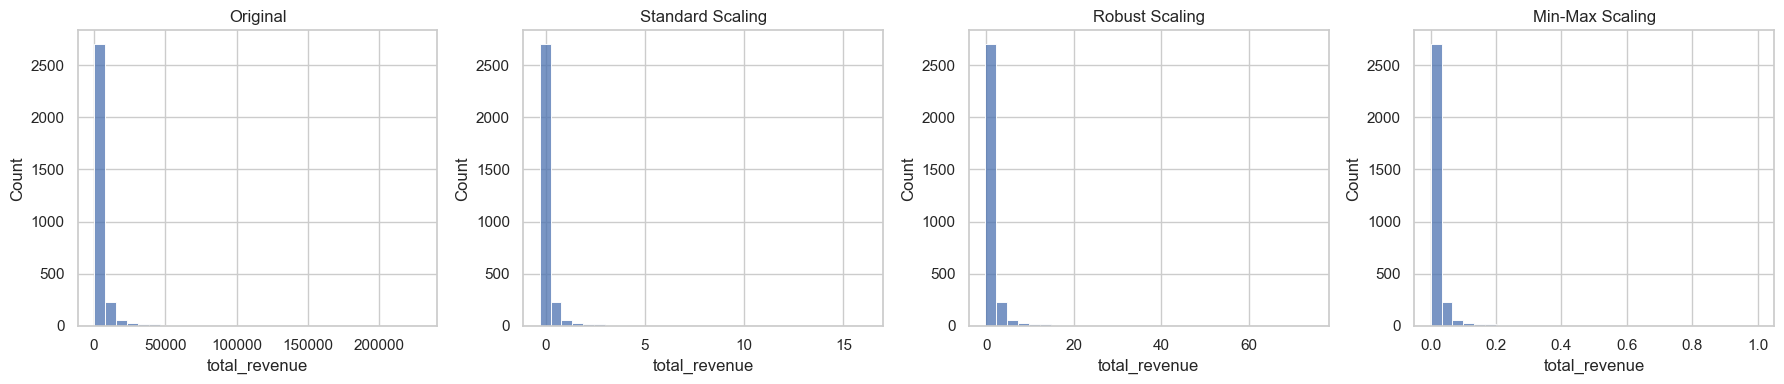

In [94]:
# Compare the distribution of one feature across scaling methods

feature_to_compare = "total_revenue"

fig, axes = plt.subplots(1, 4, figsize=(18, 4))

sns.histplot(
    scaling_data[feature_to_compare],
    bins=30,
    ax=axes[0]
)
axes[0].set_title("Original")

for i, (name, scaled_df) in enumerate(
    scaled_results.items(), start=1
):

    sns.histplot(
        scaled_df[feature_to_compare],
        bins=30,
        ax=axes[i]
    )

    axes[i].set_title(name)

plt.tight_layout()
plt.show()

### 2.6.8 Observations

**1. Log Transformation**

Log transformation substantially reduced right skewness across the selected non-negative variables. For example, the skewness of total order price decreased from 9.73 to 0.29, while seller revenue decreased from 9.05 to 0.11.

**2. Square Root Transformation**

Square Root transformation reduced skewness compared with the original distributions. However, it was generally less effective than Log, Box-Cox and Yeo-Johnson transformations for the highly skewed variables.

**3. Box-Cox Transformation**

Box-Cox transformation produced distributions with skewness values close to zero for most selected variables. For example, total order price had a transformed skewness of approximately -0.004. The transformation was applied only to strictly positive observations.
**Note:** Box-Cox transformation was applied only to strictly positive observations. Zero-valued observations were excluded because Box-Cox requires positive input values. Similarly, Log and Square Root transformations were applied to non-negative observations.

**4. Yeo-Johnson Transformation**

Yeo-Johnson transformation effectively reduced skewness across most selected variables. It also supports negative values, making it suitable for the days_late variable, which includes early and late deliveries.

**5. Feature Scaling**

Standard Scaling produced variables with approximately zero mean and unit standard deviation. Robust Scaling centered variables using their medians and interquartile ranges, while Min-Max Scaling rescaled the selected features to a range between zero and one.

**Overall Observation**

Box-Cox and Yeo-Johnson generally achieved the greatest reduction in skewness for the selected variables. The scaling comparison demonstrated how different techniques handle varying numerical ranges and extreme values.

### 2.6.9 Conclusion

Numerical transformation techniques were applied to reduce skewness in the Olist dataset. Log, Square Root, Box-Cox and Yeo-Johnson transformations were compared using skewness values and distribution plots.

Box-Cox and Yeo-Johnson generally produced distributions closer to symmetry. Yeo-Johnson was particularly useful for variables containing negative values, such as delivery lateness.

Standard, Robust and Min-Max scaling were also implemented to bring numerical features onto comparable scales.

These techniques provide alternative preprocessing approaches for subsequent statistical analysis and seller performance modelling.

### 2.7 Categorical Encoding

#### Purpose

Categorical encoding converts non-numerical variables into numerical representations that can be used in statistical analysis and machine learning.

The Olist dataset contains categorical variables such as payment type, customer state, seller state and product category. These variables require suitable encoding techniques before further analysis.

#### Methodology

The following encoding techniques are applied:

1. **One-Hot Encoding:** Converts payment type into separate binary columns.
2. **Frequency Encoding:** Replaces each category with its frequency in the training data.
3. **Target Encoding:** Replaces each category with its average late-delivery rate, calculated using training data only.
4. **Ordinal Encoding:** Represents review scores according to their natural order from 1 to 5.

Target encoding uses a training and testing split to prevent data leakage. The target variable is `is_late`, which indicates whether an order was delivered late.

### 2.7.1 Selection of Categorical Variables

The following categorical variables are selected from the master orders dataset:

- `primary_payment_type`: Main payment method used for the order.
- `customer_state`: State where the customer is located.
- `seller_state`: State where the seller is located.
- `primary_category`: Main product category associated with the order.
- `review_score`: Customer satisfaction rating ranging from 1 to 5.

The selected variables are used for different encoding techniques depending on their characteristics.

In [95]:
# Select categorical variables for encoding

categorical_data = master_orders[
    [
        "primary_payment_type",
        "customer_state",
        "seller_state",
        "primary_category",
        "review_score",
        "is_late"
    ]
].copy()

# Handle missing categorical values
categorical_columns = [
    "primary_payment_type",
    "customer_state",
    "seller_state",
    "primary_category"
]

for column in categorical_columns:
    categorical_data[column] = (
        categorical_data[column]
        .fillna("Unknown")
        .astype(str)
    )

# Remove rows where the target variable is missing
categorical_data = categorical_data.dropna(subset=["is_late"])

print("Selected categorical data shape:",
      categorical_data.shape)

display(categorical_data.head())

print("\nMissing values:")
display(categorical_data.isnull().sum())

Selected categorical data shape: (96476, 6)


,primary_payment_type,customer_state,seller_state,primary_category,review_score,is_late
0,voucher,SP,SP,housewares,4.0,0.0
1,boleto,BA,SP,perfumery,4.0,0.0
2,credit_card,GO,SP,auto,5.0,0.0
3,credit_card,RN,MG,pet_shop,5.0,0.0
4,credit_card,SP,SP,stationery,5.0,0.0



Missing values:


primary_payment_type      0
customer_state            0
seller_state              0
primary_category          0
review_score            646
is_late                   0
dtype: int64

### 2.7.2 One-Hot Encoding

One-hot encoding converts each unique payment type into a separate binary feature.

Each resulting column represents one payment category. A value of 1 indicates that the order belongs to that payment category, while 0 indicates otherwise.

This technique is suitable for payment type because it is a nominal variable without any natural ordering.

In [96]:
# One-hot encode payment type

payment_encoded = pd.get_dummies(
    categorical_data["primary_payment_type"],
    prefix="payment",
    dtype=int
)

print("One-Hot Encoded Payment Type:")
display(payment_encoded.head())

print("\nGenerated columns:")
print(payment_encoded.columns.tolist())

print("\nPayment type frequencies:")
display(
    categorical_data["primary_payment_type"]
    .value_counts()
)

One-Hot Encoded Payment Type:


,payment_Unknown,payment_boleto,payment_credit_card,payment_debit_card,payment_voucher
0,0,0,0,0,1
1,0,1,0,0,0
2,0,0,1,0,0
3,0,0,1,0,0
4,0,0,1,0,0



Generated columns:
['payment_Unknown', 'payment_boleto', 'payment_credit_card', 'payment_debit_card', 'payment_voucher']

Payment type frequencies:


primary_payment_type
credit_card    72824
boleto         19191
voucher         2977
debit_card      1483
Unknown            1
Name: count, dtype: int64

### 2.7.3 Frequency Encoding

Frequency encoding replaces each category with the number of times it appears in the dataset.

It is applied to customer state, seller state and product category.

This technique provides a compact numerical representation of high-cardinality categorical variables without creating a large number of additional columns.

In [97]:
# Frequency encoding

frequency_columns = [
    "customer_state",
    "seller_state",
    "primary_category"
]

frequency_encoded = pd.DataFrame(
    index=categorical_data.index
)

for column in frequency_columns:

    frequency_mapping = (
        categorical_data[column]
        .value_counts(normalize=True)
    )

    frequency_encoded[column + "_frequency"] = (
        categorical_data[column]
        .map(frequency_mapping)
    )

print("Frequency Encoded Variables:")
display(frequency_encoded.head())

print("\nFrequency Encoding Summary:")
display(frequency_encoded.describe())

Frequency Encoded Variables:


,customer_state_frequency,seller_state_frequency,primary_category_frequency
0,0.419742,0.709161,0.058958
1,0.033749,0.709161,0.031873
2,0.020285,0.709161,0.039305
3,0.004913,0.079274,0.017434
4,0.419742,0.709161,0.023291



Frequency Encoding Summary:


,customer_state_frequency,seller_state_frequency,primary_category_frequency
count,96476.000000,96476.000000,96476.000000
mean,0.216759,0.518941,0.050555
std,0.176423,0.297389,0.028943
min,0.000425,0.000031,0.000021
25%,0.051028,0.079274,0.028639
50%,0.128042,0.709161,0.056698
75%,0.419742,0.709161,0.077646
max,0.419742,0.709161,0.095018


### 2.7.4 Target Encoding

Target encoding replaces each category with the average value of the target variable for that category.

In this analysis, the target variable is `is_late`:

- 1 represents a late order.
- 0 represents an order that was not late.

The encoding is applied to customer state, seller state and product category.

To prevent target leakage, out-of-fold (OOF) target encoding is applied to the training data using 5-fold stratified cross-validation. Each training observation is encoded using category statistics calculated without using its own fold.

For the testing data, category statistics are calculated using the complete training dataset only.

Smoothing is applied to reduce the influence of categories with very few observations. Unseen categories are assigned the global training target mean.

In [98]:
from sklearn.model_selection import train_test_split

# Prepare features and target
target_columns = [
    "customer_state",
    "seller_state",
    "primary_category"
]

X = categorical_data[target_columns].copy()

y = categorical_data["is_late"].astype(int)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining late-order rate:", y_train.mean())
print("Testing late-order rate:", y_test.mean())

Training data shape: (77180, 3)
Testing data shape: (19296, 3)

Training late-order rate: 0.08113500906970718
Testing late-order rate: 0.08110489220563848


In [104]:

from sklearn.model_selection import StratifiedKFold

# Apply leakage-safe smoothed target encoding using 5-fold OOF encoding

target_encoded_train = pd.DataFrame(
    index=X_train.index
)

target_encoded_test = pd.DataFrame(
    index=X_test.index
)

global_mean = y_train.mean()
smoothing = 20
n_splits = 5

# Stratified folds preserve the proportion of late and non-late orders
skf = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42
)

for column in target_columns:

    # Initialize OOF encoded values
    oof_encoded = pd.Series(
        index=X_train.index,
        dtype=float
    )

    # Generate out-of-fold encodings
    for train_idx, val_idx in skf.split(X_train, y_train):

        X_fold_train = X_train.iloc[train_idx]
        y_fold_train = y_train.iloc[train_idx]

        X_fold_val = X_train.iloc[val_idx]

        fold_global_mean = y_fold_train.mean()

        # Calculate category statistics using only fold-training data
        category_stats = pd.DataFrame({
            "category": X_fold_train[column],
            "target": y_fold_train
        }).groupby("category")["target"].agg(
            ["mean", "count"]
        )

        # Apply smoothing
        category_mapping = (
            category_stats["count"] * category_stats["mean"]
            + smoothing * fold_global_mean
        ) / (
            category_stats["count"] + smoothing
        )

        # Encode validation fold
        oof_encoded.iloc[val_idx] = (
            X_fold_val[column]
            .map(category_mapping)
            .fillna(fold_global_mean)
            .values
        )

    target_encoded_train[
        column + "_target_encoded"
    ] = oof_encoded

    # Fit mapping on the complete training data for test encoding
    full_category_stats = pd.DataFrame({
        "category": X_train[column],
        "target": y_train
    }).groupby("category")["target"].agg(
        ["mean", "count"]
    )

    full_category_mapping = (
        full_category_stats["count"] * full_category_stats["mean"]
        + smoothing * global_mean
    ) / (
        full_category_stats["count"] + smoothing
    )

    # Encode testing data using training mappings only
    target_encoded_test[
        column + "_target_encoded"
    ] = (
        X_test[column]
        .map(full_category_mapping)
        .fillna(global_mean)
    )

print("Out-of-Fold Target Encoded Training Data:")
display(target_encoded_train.head())

print("\nTarget Encoded Testing Data:")
display(target_encoded_test.head())

print("\nTraining and testing encoded shapes:")
print("Training:", target_encoded_train.shape)
print("Testing:", target_encoded_test.shape)

print("\nGlobal training late-delivery rate:", global_mean)

print("\nMissing values in training encodings:")
display(target_encoded_train.isnull().sum())

print("\nMissing values in testing encodings:")
display(target_encoded_test.isnull().sum())


Out-of-Fold Target Encoded Training Data:


,customer_state_target_encoded,seller_state_target_encoded,primary_category_target_encoded
96661,0.096736,0.062165,0.087314
87263,0.058199,0.087933,0.089982
11440,0.057342,0.087242,0.080120
46058,0.096550,0.067363,0.067549
14979,0.059045,0.064246,0.076158



Target Encoded Testing Data:


,customer_state_target_encoded,seller_state_target_encoded,primary_category_target_encoded
98634,0.135610,0.087944,0.070290
76411,0.057070,0.087944,0.062372
6379,0.082777,0.087944,0.047212
87646,0.058618,0.087944,0.075798
24868,0.058618,0.087944,0.095101



Training and testing encoded shapes:
Training: (77180, 3)
Testing: (19296, 3)

Global training late-delivery rate: 0.08113500906970718

Missing values in training encodings:


customer_state_target_encoded      0
seller_state_target_encoded        0
primary_category_target_encoded    0
dtype: int64


Missing values in testing encodings:


customer_state_target_encoded      0
seller_state_target_encoded        0
primary_category_target_encoded    0
dtype: int64

### 2.7.5 Ordinal Encoding

Review score is an ordinal variable because its values have a meaningful order.

The ratings range from 1 to 5:

- 1: Very Poor
- 2: Poor
- 3: Average
- 4: Good
- 5: Excellent

The numerical representation is preserved because the existing review scores already follow this natural order.

In [100]:
# Ordinal encoding of review scores

review_score_mapping = {
    1: 1,
    2: 2,
    3: 3,
    4: 4,
    5: 5
}

ordinal_encoded = (
    categorical_data["review_score"]
    .map(review_score_mapping)
)

print("Ordinal Encoded Review Scores:")
display(ordinal_encoded.value_counts().sort_index())

print("\nReview Score Mapping:")
display(
    pd.DataFrame({
        "Original Review Score": list(review_score_mapping.keys()),
        "Ordinal Encoded Value": list(review_score_mapping.values())
    })
)

Ordinal Encoded Review Scores:


review_score
1.0     9355
2.0     2920
3.0     7917
4.0    18894
5.0    56744
Name: count, dtype: int64


Review Score Mapping:


,Original Review Score,Ordinal Encoded Value
0,1,1
1,2,2
2,3,3
3,4,4
4,5,5


### 2.7.6 Comparison of Encoding Techniques

The encoded variables are examined to understand how each technique represents categorical information.

The resulting representations are compared based on their number of generated features, numerical values and suitability for further analysis.

In [101]:
# Compare the number of features generated by each encoding technique

encoding_comparison = pd.DataFrame({
    "Encoding Technique": [
        "One-Hot Encoding",
        "Frequency Encoding",
        "Target Encoding",
        "Ordinal Encoding"
    ],
    "Original Variables": [
        "primary_payment_type",
        "customer_state, seller_state, primary_category",
        "customer_state, seller_state, primary_category",
        "review_score"
    ],
    "Number of Encoded Features": [
        payment_encoded.shape[1],
        frequency_encoded.shape[1],
        target_encoded_train.shape[1],
        1
    ]
})

display(encoding_comparison)

,Encoding Technique,Original Variables,Number of Encoded Features
0,One-Hot Encoding,primary_payment_type,5
1,Frequency Encoding,"customer_state, seller_state, primary_category",3
2,Target Encoding,"customer_state, seller_state, primary_category",3
3,Ordinal Encoding,review_score,1


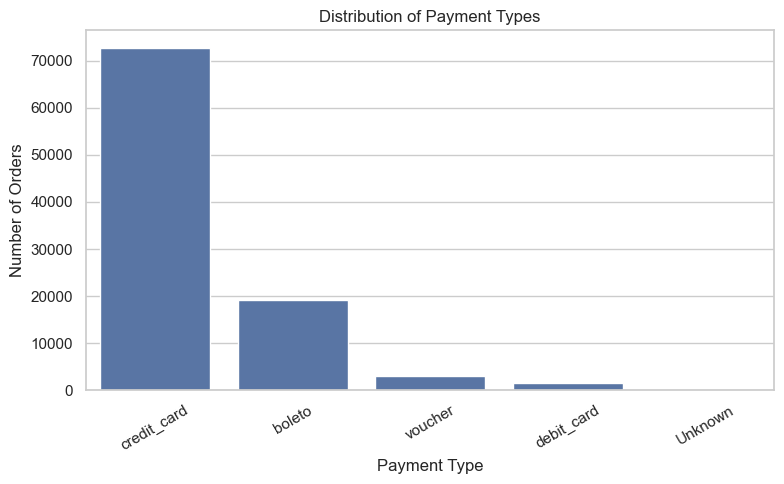

In [102]:
# Visualize payment type distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=categorical_data,
    x="primary_payment_type",
    order=categorical_data["primary_payment_type"].value_counts().index
)

plt.title("Distribution of Payment Types")
plt.xlabel("Payment Type")
plt.ylabel("Number of Orders")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

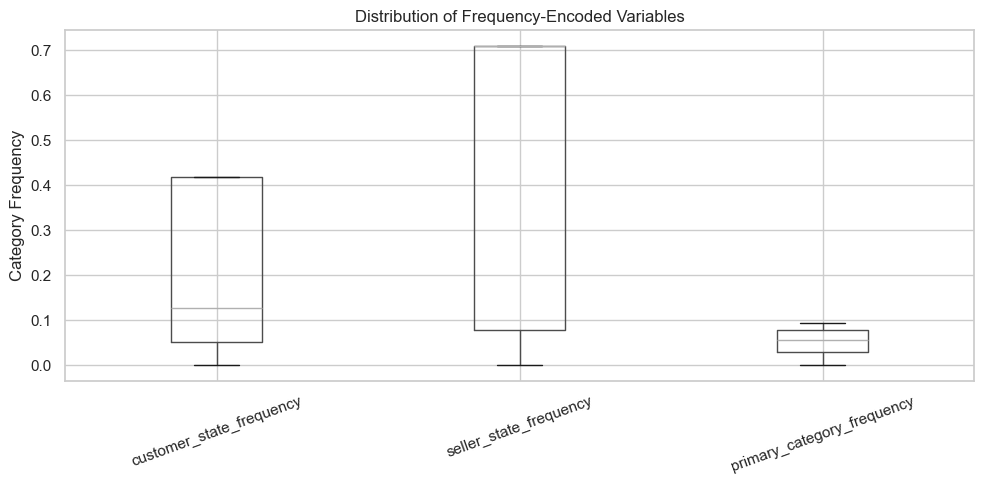

In [103]:
# Visualize frequency-encoded variables

plt.figure(figsize=(10, 5))

frequency_encoded.boxplot()

plt.title("Distribution of Frequency-Encoded Variables")
plt.ylabel("Category Frequency")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### 2.7.7 Observations

1. **One-Hot Encoding:** Payment types were converted into separate binary columns, allowing nominal payment categories to be represented numerically.

2. **Frequency Encoding:** Customer state, seller state and product category were represented using their category frequencies. This provides a compact representation without generating a separate column for every category.

3. **Target Encoding:** The selected categorical variables were represented using their smoothed late-delivery rates. The mappings were calculated using training data only, and unseen testing categories were assigned the global training mean.

4. **Ordinal Encoding:** Review scores retained their natural order from 1 to 5, preserving the ordinal nature of customer ratings.

5. **Comparison:** Different encoding techniques were used according to the characteristics of the categorical variables. One-hot encoding is suitable for nominal variables with relatively few categories, while frequency and target encoding provide compact representations of high-cardinality variables.

### 2.7.8 Conclusion

Categorical encoding was performed on the Olist dataset using One-Hot, Frequency, Target and Ordinal encoding techniques.

Payment types were converted into binary features, while customer state, seller state and product category were represented using frequency and target encoding. Review scores were retained as ordinal numerical values.

Target encoding was performed using training data only to prevent data leakage. These transformations provide numerical representations of categorical variables while preserving their relevant characteristics for further statistical analysis and machine learning applications.

### 2.8 Cyclical Encoding

#### Purpose

Cyclical encoding is used to represent time-related variables that follow repeating cycles.

In the Olist dataset, purchase month, day of the week and purchase hour are cyclical variables. Their values repeat after a fixed interval.

Using their original numerical values directly may fail to represent the relationship between the beginning and end of a cycle. For example, December and January are consecutive months, even though their numerical values are 12 and 1.

#### Methodology

Cyclical encoding is performed using sine and cosine transformations.

For a variable x with a cycle length of N:

- Sine encoding: sin(2πx/N)
- Cosine encoding: cos(2πx/N)

The following variables are encoded:

1. Purchase month with a cycle length of 12.
2. Purchase day of the week with a cycle length of 7.
3. Purchase hour with a cycle length of 24.

Both sine and cosine features are generated for each variable. The original variables are retained.

### 2.8.1 Selection of Time Variables

The following time-related variables are selected from the master orders dataset:

- `purchase_month`: Represents the month in which an order was purchased.
- `purchase_dayofweek`: Represents the day of the week on which an order was purchased.
- `purchase_hour`: Represents the hour at which an order was purchased.

These variables are used to generate cyclical sine and cosine features.

In [105]:
# Select time-related variables for cyclical encoding

cyclical_data = master_orders[
    [
        "purchase_month",
        "purchase_dayofweek",
        "purchase_hour"
    ]
].copy()

# Convert selected columns to numeric values
for column in cyclical_data.columns:
    cyclical_data[column] = pd.to_numeric(
        cyclical_data[column],
        errors="coerce"
    )

print("Selected time variables:")
display(cyclical_data.head())

print("\nDescriptive statistics:")
display(cyclical_data.describe())

print("\nMissing values:")
display(cyclical_data.isnull().sum())

Selected time variables:


,purchase_month,purchase_dayofweek,purchase_hour
0,10,0,10
1,7,1,20
2,8,2,8
3,11,5,19
4,2,1,21



Descriptive statistics:


,purchase_month,purchase_dayofweek,purchase_hour
count,99441.000000,99441.000000,99441.000000
mean,6.032220,2.755735,14.770829
std,3.232999,1.966495,5.326800
min,1.000000,0.000000,0.000000
25%,3.000000,1.000000,11.000000
50%,6.000000,3.000000,15.000000
75%,8.000000,4.000000,19.000000
max,12.000000,6.000000,23.000000



Missing values:


purchase_month        0
purchase_dayofweek    0
purchase_hour         0
dtype: int64

### 2.8.2 Sine and Cosine Transformations

Each time variable is converted into two numerical features using sine and cosine functions.

The transformation formula is:

- Sine = sin(2π × x / N)
- Cosine = cos(2π × x / N)

Where:

- x represents the original time value.
- N represents the total cycle length.

The cycle lengths are 12 for months, 7 for days of the week and 24 for hours.

The resulting features represent the cyclical position of each observation while preserving the original time variables.

In [106]:
# Create a copy for cyclical encoding
cyclical_encoded = cyclical_data.copy()

# Define cycle lengths
cycle_lengths = {
    "purchase_month": 12,
    "purchase_dayofweek": 7,
    "purchase_hour": 24
}

# Apply sine and cosine transformations
for column, period in cycle_lengths.items():

    cyclical_encoded[column + "_sin"] = np.sin(
        2 * np.pi * cyclical_encoded[column] / period
    )

    cyclical_encoded[column + "_cos"] = np.cos(
        2 * np.pi * cyclical_encoded[column] / period
    )

print("Cyclical Encoding Results:")
display(cyclical_encoded.head())

print("\nGenerated cyclical features:")
print([
    column for column in cyclical_encoded.columns
    if column.endswith("_sin") or column.endswith("_cos")
])

Cyclical Encoding Results:


,purchase_month,purchase_dayofweek,purchase_hour,purchase_month_sin,purchase_month_cos,purchase_dayofweek_sin,purchase_dayofweek_cos,purchase_hour_sin,purchase_hour_cos
0,10,0,10,-0.866025,0.500000,0.000000,1.000000,0.500000,-0.866025
1,7,1,20,-0.500000,-0.866025,0.781831,0.623490,-0.866025,0.500000
2,8,2,8,-0.866025,-0.500000,0.974928,-0.222521,0.866025,-0.500000
3,11,5,19,-0.500000,0.866025,-0.974928,-0.222521,-0.965926,0.258819
4,2,1,21,0.866025,0.500000,0.781831,0.623490,-0.707107,0.707107



Generated cyclical features:
['purchase_month_sin', 'purchase_month_cos', 'purchase_dayofweek_sin', 'purchase_dayofweek_cos', 'purchase_hour_sin', 'purchase_hour_cos']


### 2.8.3 Visualization of Cyclical Features

The sine and cosine transformations are visualized to examine how the time variables are represented in cyclical form.

The plots demonstrate how each variable follows a repeating pattern over its respective cycle.

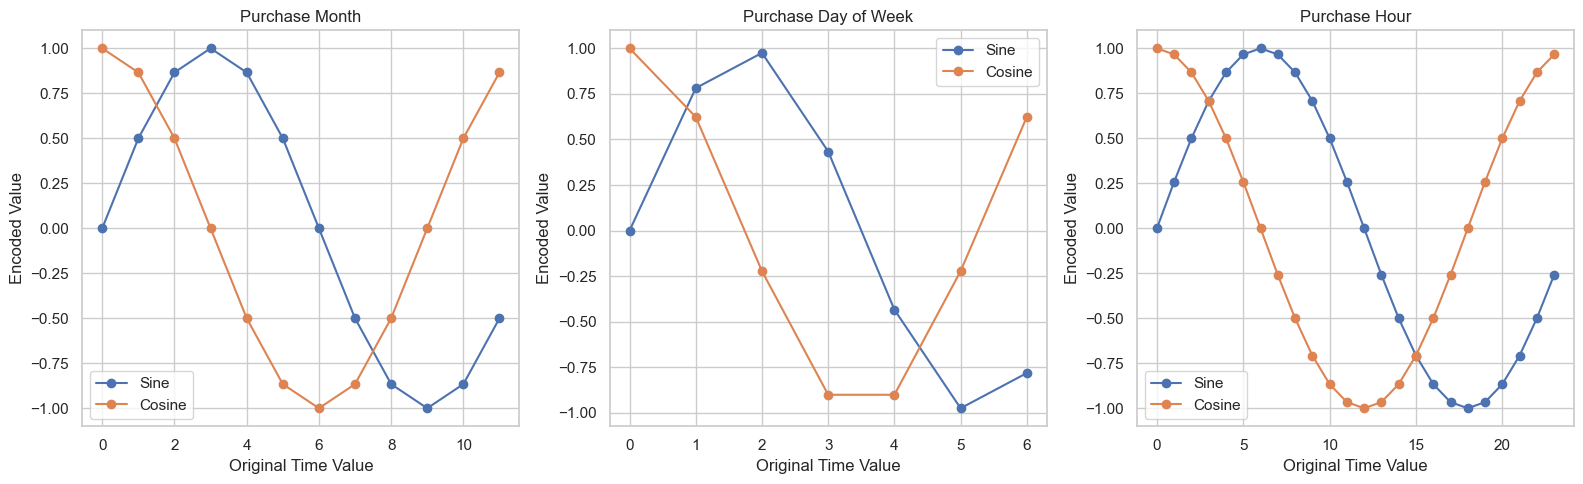

In [107]:
# Visualize the cyclical encoding of time variables

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

plot_variables = [
    ("purchase_month", 12, "Purchase Month"),
    ("purchase_dayofweek", 7, "Purchase Day of Week"),
    ("purchase_hour", 24, "Purchase Hour")
]

for ax, (column, period, title) in zip(axes, plot_variables):

    x = np.arange(period)

    sin_values = np.sin(2 * np.pi * x / period)
    cos_values = np.cos(2 * np.pi * x / period)

    ax.plot(x, sin_values, marker="o", label="Sine")
    ax.plot(x, cos_values, marker="o", label="Cosine")

    ax.set_title(title)
    ax.set_xlabel("Original Time Value")
    ax.set_ylabel("Encoded Value")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

### 2.8.4 Comparison of Original and Encoded Variables

The original time variables are compared with their newly generated sine and cosine features.

Each original variable produces two additional numerical features. The original variables are retained to preserve the initial time information.

In [108]:
# Compare original and cyclical encoded variables

comparison_columns = [
    "purchase_month",
    "purchase_month_sin",
    "purchase_month_cos",
    "purchase_dayofweek",
    "purchase_dayofweek_sin",
    "purchase_dayofweek_cos",
    "purchase_hour",
    "purchase_hour_sin",
    "purchase_hour_cos"
]

display(cyclical_encoded[comparison_columns].head(10))

print("\nOriginal number of features:", cyclical_data.shape[1])

print("Number of features after cyclical encoding:",
      cyclical_encoded.shape[1])

print("\nFinal dataset shape:", cyclical_encoded.shape)

,purchase_month,purchase_month_sin,purchase_month_cos,purchase_dayofweek,purchase_dayofweek_sin,purchase_dayofweek_cos,purchase_hour,purchase_hour_sin,purchase_hour_cos
0,10,-0.866025,0.500000,0,0.000000,1.000000,10,5.000000e-01,-8.660254e-01
1,7,-0.500000,-0.866025,1,0.781831,0.623490,20,-8.660254e-01,5.000000e-01
2,8,-0.866025,-0.500000,2,0.974928,-0.222521,8,8.660254e-01,-5.000000e-01
3,11,-0.500000,0.866025,5,-0.974928,-0.222521,19,-9.659258e-01,2.588190e-01
4,2,0.866025,0.500000,1,0.781831,0.623490,21,-7.071068e-01,7.071068e-01
5,7,-0.500000,-0.866025,6,-0.781831,0.623490,21,-7.071068e-01,7.071068e-01
6,4,0.866025,-0.500000,1,0.781831,0.623490,12,1.224647e-16,-1.000000e+00
7,5,0.500000,-0.866025,1,0.781831,0.623490,13,-2.588190e-01,-9.659258e-01
8,1,0.500000,0.866025,0,0.000000,1.000000,18,-1.000000e+00,-1.836970e-16
9,7,-0.500000,-0.866025,5,-0.974928,-0.222521,11,2.588190e-01,-9.659258e-01



Original number of features: 3
Number of features after cyclical encoding: 9

Final dataset shape: (99441, 9)


### 2.8.5 Observations

1. **Purchase Month:** The month variable was converted into sine and cosine features using a cycle length of 12. This represents the circular relationship between December and January.

2. **Purchase Day of Week:** The day-of-week variable was encoded using a cycle length of 7, preserving the repeating weekly pattern.

3. **Purchase Hour:** The hour variable was encoded using a cycle length of 24, representing the circular relationship between the last and first hours of the day.

4. **Feature Generation:** Each original time variable generated two new features: one sine feature and one cosine feature.

5. **Preservation of Original Variables:** The original time variables were retained alongside their encoded representations.

### 2.8.6 Conclusion

Cyclical encoding was successfully applied to purchase month, purchase day of the week and purchase hour using sine and cosine transformations.

The transformation represents repeating time patterns in a numerical format while preserving the relationship between the beginning and end of each cycle.

A total of six cyclical features were generated from the three original time variables. The original variables were retained, providing both the original time information and their cyclical representations for further analysis.